In [ ]:
### NEW BLOCK OF ANALYSES. Fibroblast subpopulation identification in Lung

In [1]:
import scanpy as sc
import anndata as ad
import harmonypy as hm
import numpy as np
import random

# --- 1) Load your four datasets ---
lung      = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/LUNG/Unintegrated_Lung_V2_reann.h5ad")
skin      = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/SKIN/Unintegrated_Skin_V2_reann.h5ad")
pbmc      = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/PBMCs/Unintegrated_PBMCs_V2_reann.h5ad")
synovium  = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/SYNOVIUM/Unintegrated_synovium_corr_V2_reann.h5ad")

# --- 2) Add sample IDs (needed for Harmony batch correction) ---
lung.obs["dataset"]     = "lung"
skin.obs["dataset"]     = "skin"
pbmc.obs["dataset"]     = "pbmc"
synovium.obs["dataset"] = "synovium"

np.random.seed(0)
random.seed(0)


In [2]:
import numpy as np
import scipy.sparse as sp

for dataset in skin.obs["dataset"].unique():
    idx = np.where(skin.obs["dataset"] == dataset)[0][:3]  # primi 3 indici numerici
    subset = skin.raw.X[idx, :20]
    
    if sp.issparse(subset):
        sample_values = subset.toarray()
    else:
        sample_values = subset
    
    print(f"\n── {dataset} ──")
    print(sample_values)


── skin ──
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 2. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [3]:
import numpy as np
import scipy.sparse as sp

for dataset in pbmc.obs["dataset"].unique():
    idx = np.where(pbmc.obs["dataset"] == dataset)[0][:3]  # primi 3 indici numerici
    subset = pbmc.raw.X[idx, :20]
    
    if sp.issparse(subset):
        sample_values = subset.toarray()
    else:
        sample_values = subset
    
    print(f"\n── {dataset} ──")
    print(sample_values)


── pbmc ──
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [4]:
import numpy as np
import scipy.sparse as sp

for dataset in lung.obs["dataset"].unique():
    idx = np.where(lung.obs["dataset"] == dataset)[0][:3]  # primi 3 indici numerici
    subset = lung.raw.X[idx, :5]
    
    if sp.issparse(subset):
        sample_values = subset.toarray()
    else:
        sample_values = subset
    
    print(f"\n── {dataset} ──")
    print(sample_values)


── lung ──
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]


In [5]:
for dataset in synovium.obs["dataset"].unique():
    idx = np.where(synovium.obs["dataset"] == dataset)[0][:3]  # primi 3 indici numerici
    subset = synovium.raw.X[idx, :5]
    
    if sp.issparse(subset):
        sample_values = subset.toarray()
    else:
        sample_values = subset
    
    print(f"\n── {dataset} ──")
    print(sample_values)


── synovium ──
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]]


In [6]:
print("R")

R


In [7]:
synovium.obs["cell_type_merged"].value_counts().sort_values()
synovium.obs["disease"].unique()

['SSc', 'Trauma']
Categories (2, object): ['SSc', 'Trauma']

In [8]:
skin.obs["sample"]

0         SC124
1         SC124
2         SC124
3         SC124
4         SC124
          ...  
126185    SC224
126186    SC224
126187    SC224
126188    SC224
126189    SC224
Name: sample, Length: 126190, dtype: category
Categories (52, object): ['SC1', 'SC2', 'SC4', 'SC5', ..., 'SC245', 'SC247', 'SC248', 'SC254']

In [9]:
pbmc.obs["sample"]

0                 HD5
1                 HD5
2                 HD5
3                 HD5
4                 HD5
             ...     
251896    SSc1_before
251897    SSc1_before
251898    SSc1_before
251899    SSc1_before
251900    SSc1_before
Name: sample, Length: 251901, dtype: category
Categories (29, object): ['HD1', 'HD2', 'HD3', 'HD4', ..., 'SSc18', 'SSc19', 'SSc20', 'SSc21']

In [10]:
lung.obs["sample"]

0         SC109SSCUP
1         SC109SSCUP
2         SC109SSCUP
3         SC109SSCUP
4         SC109SSCUP
             ...    
224291         SC313
224292         SC313
224293         SC313
224294         SC313
224295         SC313
Name: sample, Length: 224296, dtype: category
Categories (24, object): ['SC45NOR', 'SC51SSCLOW', 'SC52SSCUP', 'SC56NOR', ..., 'SC323', 'SC333', 'SC334', 'SC335']

In [11]:
#if "cell_state" in synovium.obs.columns:
#    synovium.obs = synovium.obs.rename(columns={"cell_state": "cell_type"})

In [12]:
synovium.obs["cell_type"].value_counts().sort_values()


cell_type
E5: Lymphatic                        15
M8: LAMP3+ DCs                       28
M5: DC1                              40
M7: DC4                              54
SF2: CHI3L2+ intermediate            71
M9: pDCs                             87
Pericytes                           183
M4: S100A12+ monocytes              303
T2: CD4+ CXCL13+ Tfh/Tph            453
NK: NK cells                        464
vSMC                                493
T3: CD4+ FOXP3+ Treg                514
M6: CD1C+ DCs (DC2/DC3)             573
SF7: CXCL14+ sublining              638
T5: THEMIS+ naive T cells           684
E3: SPARC+ capillary                779
E4: ARL15+ arterial                 812
SF5: FKBP5+ sublining               840
SF4: POSTN+ sublining               948
SF6: FOSB+ sublining               1041
T4: CD8+ GRZMK+ T cells            1076
SF8: MFAP5+ sublining              1093
M3: SPP1+ macrophages              1392
M2: MERTK- macrophages             1582
E2: LIFR1+ venous             

In [13]:
lung.obs["cell_type"].value_counts().sort_values()

cell_type
Mesothelium                         63
T cells proliferating               65
Goblet (subsegmental)               70
DC1                                 75
SMG duct                            78
Alveolar Mph MT-positive            80
Migratory DCs                      100
Multiciliated (nasal)              107
Plasmacytoid DCs                   119
AT2 proliferating                  121
Goblet (bronchial)                 122
SM activated stress response       126
Lymphatic EC differentiating       133
Hillock-like                       166
Myofibroblasts                     199
AT0                                468
Alveolar Mph proliferating         632
Club (nasal)                       649
Pericytes                          765
EC aerocyte capillary             1021
Club (non-nasal)                  1026
Alveolar Mph CCL3+                1102
B cells                           1211
Lymphatic EC mature               1301
Peribronchial fibroblasts         1508
EC arterial    

In [73]:
#lung.obs = lung.obs.drop(columns=["Condition_x", "Condition_y"])
#skin.obs = skin.obs.drop(columns=["Condition_x", "Condition_y"])
#pbmc.obs = pbmc.obs.drop(columns=["Condition_x", "Condition_y"])

In [13]:
import pandas as pd

meta = pd.read_csv("Sample_Metadata_Lung.csv", sep=";")  # or metadata.csv if it's comma-separated
# 3. Merge with adata.obs
lung.obs["orig_index"] = lung.obs.index
#lung.obs = lung.obs.merge(meta, on="sample", how="left")
# Restore the original index
lung.obs = lung.obs.set_index("orig_index")

import pandas as pd




import pandas as pd
GSE138669 = pd.read_csv("/home/ciperi/data/Atlas_SSC/SKIN/GSE138669/GSE138669_metadata.tsv", sep='\t')
GSE138669 = GSE138669[['title', 'condition:ch1']]
GSE138669 = GSE138669.rename(columns={'condition:ch1': 'Condition'})

import pandas as pd
#GSE195452 = pd.read_csv("/home/ciperi/data/Atlas_SSC/SKIN/GSE195452/GSE195452_metadata.tsv", sep='\t')
# Create a new column based on pattern matching
#GSE195452['Condition'] = GSE195452['patient id:ch1'].apply(
#    lambda x: 'CONTROL' if 'Ctrl' in x else 'SSC'
#)

#GSE195452 = GSE195452[['patient id:ch1', 'Condition']]
GSE138669 = GSE138669.rename(columns={'patient id:ch1': 'title'})

import pandas as pd
GSE209635 = pd.read_csv("/home/ciperi/data/Atlas_SSC/SKIN/GSE209635/GSE209635_metadata.tsv", sep='\t')
# Create a new column based on pattern matching
GSE209635['Condition'] = GSE209635['treatment:ch1'].apply(
    lambda x: 'CTRL' if 'CONTROL' in x else 'SSC'
)

GSE209635 = GSE209635[['title', 'Condition']]
print(GSE209635)
#meta = pd.concat([GSE138669,GSE195452, GSE209635 ], ignore_index=True)
meta = pd.concat([GSE138669, GSE209635 ], ignore_index=True)
meta = meta.rename(columns={'title': 'sample'})

meta['Condition'] = meta['Condition'].apply(
    lambda x: 'CTRL' if 'CONTROL' in x else 'SSC'
)
# 1. Load your metadata
#meta = pd.read_csv("Sample_Metadata_Skin.csv", sep=";")  # or metadata.csv if it's comma-separated
# 3. Merge with adata.obs
skin.obs["orig_index"] = skin.obs.index
#skin.obs = skin.obs.merge(meta, on="sample", how="left")
# Restore the original index
skin.obs = skin.obs.set_index("orig_index")


import pandas as pd
GSE195452 = pd.read_csv("/home/ciperi/data/Atlas_SSC/PBMCs/E-GEAD-872/E-GEAD-872_metadata.tsv", sep='\t')
# Remove the last two rows
GSE195452 = GSE195452.iloc[:-2]
# Create a new column based on the prefix
GSE195452['Condition'] = GSE195452['geo_accession'].apply(
    lambda x: 'CTRL' if x.startswith('HD_') else 'SSC'
)
GSE195452 = GSE195452[['title', 'Condition']]
import pandas as pd
meta = pd.concat([GSE195452], ignore_index=True)
meta = meta.rename(columns={'title': 'sample'})
meta["sample"] = meta["sample"].str.replace("_", "", n=1)

# 1. Load your metadata
#meta = pd.read_csv("Sample_Metadata_Skin.csv", sep=";")  # or metadata.csv if it's comma-separated
pbmc.obs["orig_index"] = pbmc.obs.index
#pbmc.obs = pbmc.obs.merge(meta, on="sample", how="left")
# Restore the original index
pbmc.obs = pbmc.obs.set_index("orig_index")


synovium.obs["orig_index"] = synovium.obs.index
synovium.obs["Condition"] = synovium.obs["disease"]
synovium.obs["Condition"] = synovium.obs["disease"].apply(
    lambda x: "CTRL" if "Trauma" in x else "SSC"
)

    title Condition
0   SC159       SSC
1   SC160       SSC
2   SC163       SSC
3   SC169       SSC
4   SC164       SSC
5   SC184       SSC
6   SC202       SSC
7   SC212       SSC
8   SC226       SSC
9   SC224       SSC
10  SC237       SSC
11  SC247       SSC
12  SC229       SSC
13  SC230       SSC
14  SC240       SSC
15  SC172       SSC
16  SC178       SSC
17  SC176       SSC
18  SC183       SSC
19  SC177       SSC
20  SC190       SSC
21  SC214       SSC
22  SC225       SSC
23  SC236       SSC
24  SC235       SSC
25  SC245       SSC
26  SC254       SSC
27  SC239       SSC
28  SC238       SSC
29  SC248       SSC


In [14]:
skin.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,time:ch1,treatment:ch1,predicted_doublet,doublet_score,cell_type,cell_type_IPF,leiden_r2,leiden_r0.4,Condition,leiden_r2_cellannot_SKIN
orig_index,,,,,,,,,,,,,,,,,,,,,
0,1700,SC124,6970.0,1700,12.941177,39.110473,0.000000,0.0,4.100000,GSE138669,...,NaN,NaN,0,0.070652,Undifferentiated KC,T_CD4,0,0,CONTROL,0
1,1580,SC124,7385.0,1580,2.626947,27.217332,0.000000,0.0,4.674051,GSE138669,...,NaN,NaN,0,0.029197,DC1,cDC2,11,5,CONTROL,6
2,815,SC124,2085.0,815,11.750600,7.769784,0.047962,0.0,2.558282,GSE138669,...,NaN,NaN,0,0.029197,Differentiated KC,Basal,8,1,CONTROL,7
3,1183,SC124,4538.0,1183,4.451300,48.677832,0.000000,0.0,3.836010,GSE138669,...,NaN,NaN,0,0.151786,Undifferentiated KC,Basal,0,0,CONTROL,0
4,1471,SC124,3568.0,1471,14.125560,16.704036,0.028027,0.0,2.425561,GSE138669,...,NaN,NaN,0,0.023973,Differentiated KC,Basal,8,1,CONTROL,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126185,798,SC224,1817.0,798,2.751789,25.261420,0.055036,0.0,2.276942,GSE209635,...,TOFA-Bsl,TOFA,0,0.101351,Fibroblast,T_CD4,37,4,SSC,12
126186,387,SC224,3316.0,387,2.352232,10.434258,72.285885,0.0,8.568475,GSE209635,...,TOFA-Bsl,TOFA,0,0.011561,Erythrocytes,Macrophage_Alveolar,21,7,SSC,30
126187,1461,SC224,4021.0,1461,2.760507,22.407362,0.149217,0.0,2.752225,GSE209635,...,TOFA-Bsl,TOFA,0,0.042017,Fibroblast,Fibroblast,36,4,SSC,13


In [15]:
lung.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,patientcorecode:ch1,Sex:ch1,predicted_doublet,doublet_score,cell_type,cell_type_IPF,leiden_r2,leiden_r0.4,Condition,leiden_r2_cellannot_LUNG
orig_index,,,,,,,,,,,,,,,,,,,,,
0,214,SC109SSCUP,347.0,214,25.072047,16.138329,0.000000,0.0,1.621495,GSE128169,...,NaN,NaN,0,0.029197,B cells,Macrophage_Alveolar,0,0,SSC,0
1,1814,SC109SSCUP,6536.0,1814,4.345165,22.995716,0.000000,0.0,3.603087,GSE128169,...,NaN,NaN,0,0.015244,Classical monocytes,cMonocyte,10,6,SSC,9
2,3219,SC109SSCUP,19483.0,3219,7.042037,12.369758,0.010265,0.0,6.052501,GSE128169,...,NaN,NaN,0,0.019355,Classical monocytes,Macrophage,5,6,SSC,13
3,888,SC109SSCUP,2937.0,888,9.635682,2.110998,0.000000,0.0,3.307432,GSE128169,...,NaN,NaN,0,0.059406,AT2,ATII,22,4,SSC,18
4,683,SC109SSCUP,1194.0,683,0.753769,2.093802,0.000000,0.0,1.748170,GSE128169,...,NaN,NaN,0,0.059406,Multiciliated,Ciliated,19,8,SSC,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
224291,1720,SC313,5284.0,1720,4.258138,15.972748,0.000000,0.0,3.072093,GSE212109,...,nan,nan,0,0.050000,MIXED,Macrophage,14,7,CTRL,1
224292,472,SC313,1220.0,472,2.131147,19.344263,0.000000,0.0,2.584746,GSE212109,...,nan,nan,0,0.008242,Classical monocytes,Macrophage,14,7,CTRL,9
224293,840,SC313,1883.0,840,8.921933,5.469995,0.053107,0.0,2.241667,GSE212109,...,nan,nan,0,0.050000,Classical monocytes,Macrophage,14,7,CTRL,12


In [16]:
pbmc.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,Factor_Value[disease],dataset,predicted_doublet,doublet_score,cell_type,cell_type_Low,leiden_r2,leiden_r0.4,Condition,leiden_r2_cellannot_PBMC
orig_index,,,,,,,,,,,,,,,,,,,,,
0,1612,HD5,5384.0,1612,6.240713,1.411590,0.000000,0.000000,3.339950,E-GEAD-872,...,NaN,pbmc,0,0.002500,T cells MT,Tcm/Naive helper T cells,0,0,CONTROL,0
1,1619,HD5,4838.0,1619,1.054155,13.290615,0.000000,0.000000,2.988264,E-GEAD-872,...,NaN,pbmc,0,0.035156,Natural Killer,Tem/Temra cytotoxic T cells,9,7,CONTROL,8
2,1808,HD5,4460.0,1808,2.174888,16.053812,0.000000,0.000000,2.466814,E-GEAD-872,...,NaN,pbmc,0,0.023973,Natural Killer,CD16+ NK cells,18,7,CONTROL,10
3,583,HD5,2108.0,583,5.075901,2.561670,0.000000,0.000000,3.615780,E-GEAD-872,...,NaN,pbmc,0,0.002500,T cells MT,Tcm/Naive helper T cells,0,0,CONTROL,0
4,1724,HD5,10381.0,1724,0.587612,9.748579,0.000000,0.009633,6.021462,E-GEAD-872,...,NaN,pbmc,0,0.050000,Natural Killer,Tcm/Naive helper T cells,7,4,CONTROL,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251896,1706,SSc1_before,4763.0,1706,6.928407,3.611169,0.000000,0.000000,2.791911,E-GEAD-872,...,NaN,pbmc,0,0.015244,Classical monocytes,Classical monocytes,26,10,SSC,17
251897,2381,SSc1_before,7432.0,2381,1.735737,12.405813,0.000000,0.000000,3.121378,E-GEAD-872,...,NaN,pbmc,0,0.005236,Classical monocytes,Classical monocytes,38,14,SSC,25
251898,2840,SSc1_before,10471.0,2840,1.852736,16.426320,0.009550,0.000000,3.686972,E-GEAD-872,...,NaN,pbmc,0,0.011561,Classical monocytes,Classical monocytes,38,14,SSC,24


In [17]:
meta

,sample,Condition
0,SSc1_before,SSC
1,SSc1_onset,SSC
2,SSc1_after,SSC
3,SSc2,SSC
4,SSc3,SSC
5,SSc4,SSC
6,SSc5,SSC
7,SSc6,SSC
8,SSc7,SSC
9,SSc8,SSC


In [18]:
import scanpy as sc
import anndata as ad
import harmonypy as hm
import numpy as np


# --- 3) Concatenate all datasets ---
adata_all = ad.concat(
    [lung, skin, pbmc, synovium],
    join="outer",                # merge genes using union
    keys=["lung", "skin", "pbmc", "synovium"],
    label="tissue",
    index_unique=None,           # prevents suffixes in obs names
    merge="same"                 # merges only obs/var columns identical across datasets
)

adata_all.X = adata_all.X.copy()  # Prevent views

print(f"Combined dataset has {adata_all.n_obs} cells and {adata_all.n_vars} genes.")


/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Combined dataset has 635898 cells and 22446 genes.


In [19]:
adata_all.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,fibrosis,therapy,autoantibodies,seurat_clusters,cell_type_merged,cell_state,cell_state_short,leiden_r2_cellannot_SYNOVIUM,orig_index,tissue
0,214,SC109SSCUP,347.0,214,25.072047,16.138329,0.000000,0.000000,1.621495,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung
1,1814,SC109SSCUP,6536.0,1814,4.345165,22.995716,0.000000,0.000000,3.603087,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung
2,3219,SC109SSCUP,19483.0,3219,7.042037,12.369758,0.010265,0.000000,6.052501,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung
3,888,SC109SSCUP,2937.0,888,9.635682,2.110998,0.000000,0.000000,3.307432,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung
4,683,SC109SSCUP,1194.0,683,0.753769,2.093802,0.000000,0.000000,1.748170,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SB-095_TTTGGTTAGCACTCTA-1-GSE00000,5773,SB-095,25481.0,5773,4.528864,4.674071,0.039245,0.000000,4.413823,GSE00000,...,high,no therapy,RNA pol III,2.0,Macrophages,M1:_MERTK+_SELENOP+_macrophages,M1,3,SB-095_TTTGGTTAGCACTCTA-1-GSE00000,synovium
SB-095_TTTGGTTGTCGTGATT-1-GSE00000,5180,SB-095,20068.0,5180,8.217062,17.002192,0.004983,0.014949,3.874131,GSE00000,...,high,no therapy,RNA pol III,0.0,Endothelial cells,E1:_ICAM1+_venous,E1,2,SB-095_TTTGGTTGTCGTGATT-1-GSE00000,synovium
SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,6922,SB-095,45053.0,6922,6.740949,7.613256,0.002220,0.000000,6.508668,GSE00000,...,high,no therapy,RNA pol III,0.0,Macrophages,M0:_MERTK+_TIMD4+_macrophages,M0,22,SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,synovium
SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,4866,SB-095,20985.0,4866,5.127472,7.719800,0.009531,0.000000,4.312577,GSE00000,...,high,no therapy,RNA pol III,1.0,Macrophages,M1:_MERTK+_SELENOP+_macrophages,M1,10,SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,synovium


NORMALIZATION COMPARABILITY CHECK

[1/6] Loading dataset...
✓ Loaded: 635,898 cells × 22,446 genes
  Batches: ['E-GEAD-872', 'GSE00000', 'GSE128169', 'GSE138669', 'GSE209635', 'GSE212109']

[3/6] Comparing value distributions across batches...
  (Using ALL cells - no subsampling)
  Processing E-GEAD-872: 251,901 cells...
  Processing GSE00000: 33,511 cells...
  Processing GSE128169: 67,791 cells...
  Processing GSE138669: 63,182 cells...
  Processing GSE209635: 63,008 cells...
  Processing GSE212109: 156,505 cells...
  → Saved: check_1_value_distributions.png
     (Distributions should look similar if normalization worked)


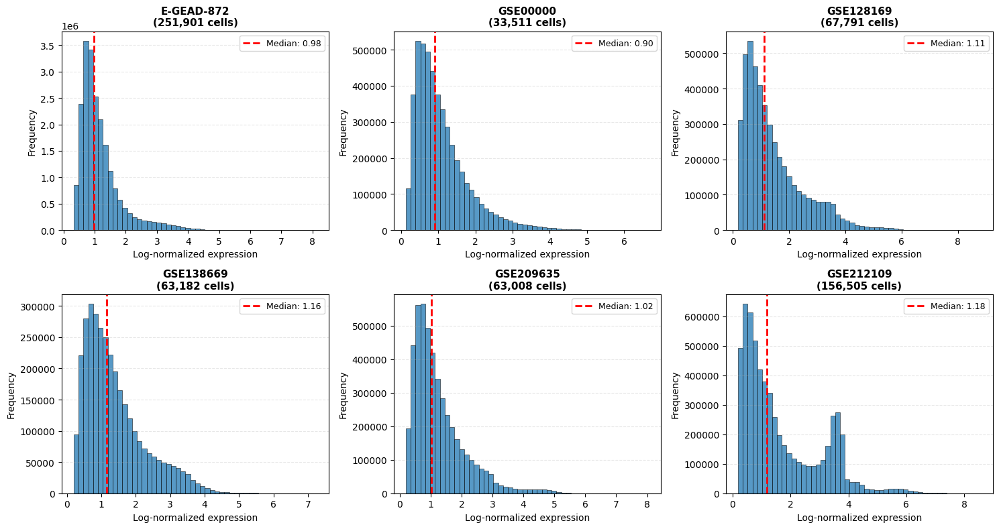

In [20]:

import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations


# ═══════════════════════════════════════════════════════════
# CONFIGURAZIONE
# ═══════════════════════════════════════════════════════════
BATCH_KEY = "batch"
CELLTYPE_KEY = "cell_group"

print("="*70)
print("NORMALIZATION COMPARABILITY CHECK")
print("="*70)

# ═══════════════════════════════════════════════════════════
# 1. CARICA DATI
# ═══════════════════════════════════════════════════════════

print("\n[1/6] Loading dataset...")
# Assume adata_all already loaded
print(f"✓ Loaded: {adata_all.n_obs:,} cells × {adata_all.n_vars:,} genes")

batches = sorted(adata_all.obs[BATCH_KEY].unique())
print(f"  Batches: {batches}")



print("\n[3/6] Comparing value distributions across batches...")
print("  (Using ALL cells - no subsampling)")

# Calculate grid layout
n_batches = len(batches)
n_cols = min(3, n_batches)
n_rows = int(np.ceil(n_batches / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
if n_batches == 1:
    axes = np.array([axes])
axes = axes.flatten()

for idx, batch in enumerate(batches):
    mask = adata_all.obs[BATCH_KEY] == batch
    batch_data = adata_all[mask]
    
    print(f"  Processing {batch}: {batch_data.n_obs:,} cells...")
    
    # Extract ALL values (no subsampling)
    if hasattr(batch_data.X, 'toarray'):
        # Sparse matrix - sample genes to avoid memory issues
        # Take all cells but sample 1000 random genes
        n_genes_sample = min(1000, batch_data.n_vars)
        gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
        values = batch_data.X[:, gene_idx].toarray().flatten()
    else:
        # Dense matrix - can handle all
        if batch_data.n_obs * batch_data.n_vars > 10_000_000:
            # Too big - sample
            n_genes_sample = min(1000, batch_data.n_vars)
            gene_idx = np.random.choice(batch_data.n_vars, n_genes_sample, replace=False)
            values = batch_data.X[:, gene_idx].flatten()
        else:
            values = np.array(batch_data.X).flatten()
    
    # Remove zeros for clearer visualization
    values_nonzero = values[values > 0]
    
    # Plot histogram
    axes[idx].hist(values_nonzero, bins=50, alpha=0.75, edgecolor='black', linewidth=0.5)
    axes[idx].axvline(np.median(values_nonzero), color='red', linestyle='--', 
                      linewidth=2, label=f'Median: {np.median(values_nonzero):.2f}')
    
    axes[idx].set_title(f"{batch}\n({batch_data.n_obs:,} cells)", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Log-normalized expression", fontsize=10)
    axes[idx].set_ylabel("Frequency", fontsize=10)
    axes[idx].legend(fontsize=9)
    axes[idx].grid(axis='y', alpha=0.3, linestyle='--')

# Hide empty subplots
for idx in range(n_batches, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
print("  → Saved: check_1_value_distributions.png")
print("     (Distributions should look similar if normalization worked)")
#plt.close()

In [21]:
import pandas as pd

obs = adata_all.obs

# Number of unique patients per batch
patients_per_batch = obs.groupby("batch")["sample"].nunique()

# Number of unique patients per batch *and condition*
patients_condition = (
    obs.groupby(["batch", "Condition"])["sample"]
       .nunique()
       .unstack(fill_value=0)
)
# Rinomina le colonne per chiarezza
patients_condition.columns = [f"n_patients_{col}" for col in patients_condition.columns]

# Number of cells per batch
cells_per_batch = obs["batch"].value_counts().sort_index()

# Tissues represented in each batch
tissues_per_batch = obs.groupby("batch")["tissue"].unique()

# List of patient IDs per batch
patients_list = obs.groupby("batch")["sample"].unique()

# Combine everything into a single summary table
summary = pd.DataFrame({
    "n_patients_total": patients_per_batch,
    "n_cells": cells_per_batch,
    "tissues": tissues_per_batch,
    "patient_ids": patients_list
})

# Aggiungi per-condition patient counts
summary = pd.concat([summary, patients_condition], axis=1)

print(summary)

            n_patients_total  n_cells  \
batch                                   
E-GEAD-872                29   251901   
GSE00000                   9    33511   
GSE128169                 13    67791   
GSE138669                 22    63182   
GSE209635                 30    63008   
GSE212109                 11   156505   

                                                      tissues  \
batch                                                           
E-GEAD-872  ['pbmc']
Categories (4, object): ['lung', 'ski...   
GSE00000    ['synovium']
Categories (4, object): ['lung', ...   
GSE128169   ['lung']
Categories (4, object): ['lung', 'ski...   
GSE138669   ['skin']
Categories (4, object): ['lung', 'ski...   
GSE209635   ['skin']
Categories (4, object): ['lung', 'ski...   
GSE212109   ['lung']
Categories (4, object): ['lung', 'ski...   

                                                  patient_ids  \
batch                                                           
E-GEAD-872  ['HD5', 

/tmp/ipykernel_3497815/196286925.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patients_per_batch = obs.groupby("batch")["sample"].nunique()
/tmp/ipykernel_3497815/196286925.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs.groupby(["batch", "Condition"])["sample"]
/tmp/ipykernel_3497815/196286925.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tissues_per_batch = obs.groupby("batch")["tissue"].unique()

In [22]:
adata_all

AnnData object with n_obs × n_vars = 635898 × 22446
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'characteristics_ch1', 'characteristics_ch1.1', 'characteristics_ch1.2', 'characteristics_ch1.3', 'molecule_ch1', 'extract_protocol_ch1', 'extract_protocol_ch1.1', 'taxid_ch1', 'description', 'description.1', 'description.2', 'data_processing', 'data_processing.1', 'data_processing.2', 'data_processing.3', 'data_processing.4', 'platform_id', 'contact_name', 'contact_laboratory', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip_postal_code', 'contact_country', 'data_row_count', 'instrument_model', 'library_selection', 'library_source', 'library_strategy', 'relation', 'supple

In [23]:
adata_all.obs["cell_type"].unique()

['B cells', 'Classical monocytes', 'AT2', 'Multiciliated', 'Alveolar macrophages', ..., 'SF2: CHI3L2+ intermediate', 'M5: DC1', 'T2: CD4+ CXCL13+ Tfh/Tph', 'M9: pDCs', 'M8: LAMP3+ DCs']
Length: 74
Categories (74, object): ['AT1', 'AT2', 'Adventitial fibroblasts', 'Alveolar fibroblasts', ..., 'T cells MT', 'Undifferentiated KC', 'pDC', 'vSMC']

In [24]:
lung.obs["Condition"].unique()

['SSC', 'CTRL']
Categories (2, object): ['CTRL', 'SSC']

In [25]:
synovium.obs["Condition"].unique()

['SSC', 'CTRL']
Categories (2, object): ['SSC', 'CTRL']

In [26]:
# --- 4) Highly Variable Genes ---
sc.pp.highly_variable_genes(adata_all, flavor="seurat", n_top_genes=1000)

# DO NOT subset the object
# adata_all = adata_all[:, adata_all.var["highly_variable"]].copy()   

# --- 5) PCA using only HVGs ---
sc.tl.pca(adata_all, use_highly_variable=True, svd_solver="arpack")

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


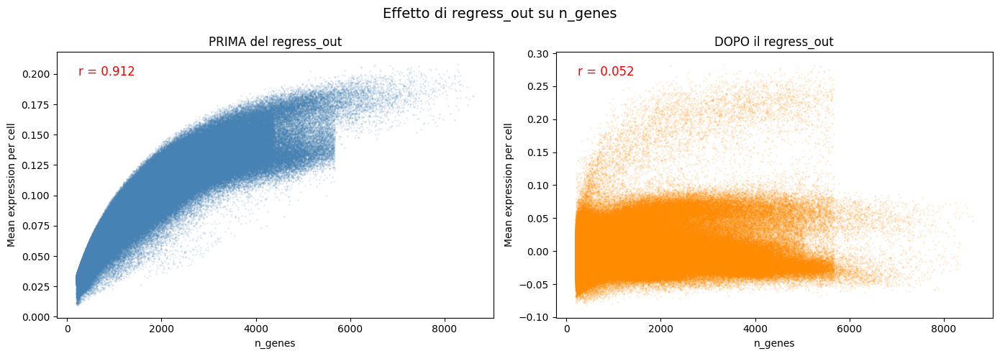

n_genes — Correlazione PRIMA: 0.9118 | DOPO: 0.0521


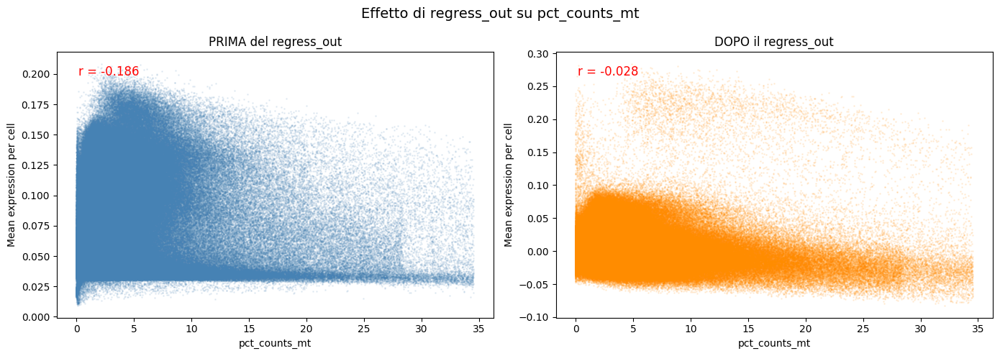

pct_counts_mt — Correlazione PRIMA: -0.1857 | DOPO: -0.0277


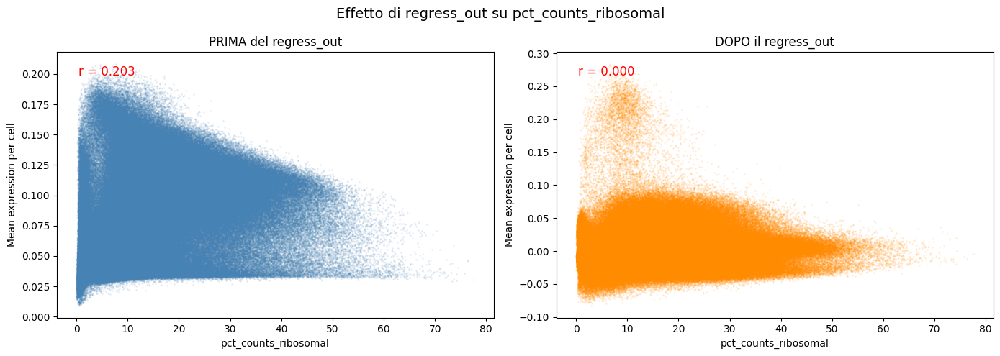

pct_counts_ribosomal — Correlazione PRIMA: 0.2034 | DOPO: 0.0000

Correlazione n_genes vs PC1: -0.0128 | PC2: -0.0394

Correlazione pct_counts_mt vs PC1: -0.0545 | PC2: 0.0151

Correlazione pct_counts_ribosomal vs PC1: 0.0000 | PC2: 0.0000


2026-04-12 14:44:47,852 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-04-12 14:45:10,360 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-04-12 14:45:11,689 - harmonypy - INFO - Iteration 1 of 25
2026-04-12 14:48:41,175 - harmonypy - INFO - Iteration 2 of 25
2026-04-12 14:52:06,147 - harmonypy - INFO - Iteration 3 of 25
2026-04-12 14:55:37,749 - harmonypy - INFO - Converged after 3 iterations
/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [27]:
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
import numpy as np

# ── SUBSET HVG ───────────────────────────────────────────────────────────────
adata_all_hvg = adata_all[:, adata_all.var["highly_variable"]].copy()

# ── REGRESS OUT ───────────────────────────────────────────────────────────────
sc.pp.regress_out(adata_all_hvg, ["n_genes"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_mt"])
sc.pp.regress_out(adata_all_hvg, ["pct_counts_ribosomal"])

# ── VALORI PRE/POST ───────────────────────────────────────────────────────────
mean_expr_before = np.array(adata_all.X.mean(axis=1)).flatten()
mean_expr_after  = np.array(adata_all_hvg.X.mean(axis=1)).flatten()

n_genes          = adata_all_hvg.obs["n_genes"].values
pct_counts_mt    = adata_all_hvg.obs["pct_counts_mt"].values
pct_counts_rb    = adata_all_hvg.obs["pct_counts_ribosomal"].values

# ── FUNZIONE HELPER ───────────────────────────────────────────────────────────
def plot_regress_validation(var_values, var_name, before, after):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # nuova figura ogni volta

    corr_before = np.corrcoef(var_values, before)[0, 1]
    corr_after  = np.corrcoef(var_values, after)[0, 1]

    axes[0].scatter(var_values, before, alpha=0.1, s=1, color="steelblue")
    axes[0].set_xlabel(var_name)
    axes[0].set_ylabel("Mean expression per cell")
    axes[0].set_title("PRIMA del regress_out")
    axes[0].text(0.05, 0.95, f"r = {corr_before:.3f}", transform=axes[0].transAxes,
                 fontsize=12, color="red", va="top")

    axes[1].scatter(var_values, after, alpha=0.1, s=1, color="darkorange")
    axes[1].set_xlabel(var_name)
    axes[1].set_ylabel("Mean expression per cell")
    axes[1].set_title("DOPO il regress_out")
    axes[1].text(0.05, 0.95, f"r = {corr_after:.3f}", transform=axes[1].transAxes,
                 fontsize=12, color="red", va="top")

    plt.suptitle(f"Effetto di regress_out su {var_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print(f"{var_name} — Correlazione PRIMA: {corr_before:.4f} | DOPO: {corr_after:.4f}")

# ── PLOT ──────────────────────────────────────────────────────────────────────
plot_regress_validation(n_genes,       "n_genes",            mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_mt, "pct_counts_mt",      mean_expr_before, mean_expr_after)
plot_regress_validation(pct_counts_rb, "pct_counts_ribosomal", mean_expr_before, mean_expr_after)

# ── PCA ───────────────────────────────────────────────────────────────────────
sc.tl.pca(adata_all_hvg, svd_solver="arpack")

for var_values, var_name in [
    (n_genes,       "n_genes"),
    (pct_counts_mt, "pct_counts_mt"),
    (pct_counts_rb, "pct_counts_ribosomal"),
]:
    corr_pc1 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 0])[0, 1]
    corr_pc2 = np.corrcoef(var_values, adata_all_hvg.obsm["X_pca"][:, 1])[0, 1]
    print(f"\nCorrelazione {var_name} vs PC1: {corr_pc1:.4f} | PC2: {corr_pc2:.4f}")

# ── HARMONY + UMAP ───────────────────────────────────────────────────────────
sce.pp.harmony_integrate(adata_all_hvg, "sample", max_iter_harmony=25)
sc.pp.neighbors(adata_all_hvg, use_rep="X_pca_harmony", n_neighbors=15)
sc.tl.umap(adata_all_hvg)

In [29]:
#import scanpy as sc
#import scanpy.external as sce
#sce.pp.harmony_integrate(adata_all, "sample")

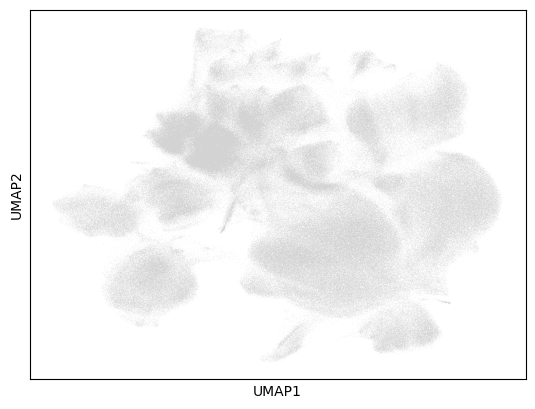

✅ Harmony integration completed and UMAP computed!


In [28]:
# --- 7) Recompute neighbors + UMAP using Harmony embedding ---
#sc.pp.neighbors(adata_all, use_rep="X_pca_harmony", n_neighbors=15, n_pcs=50)
#sc.tl.umap(adata_all)
sc.pl.umap(adata_all_hvg)
# --- 8) Save the integrated object ---
#adata_all.write_h5ad("/home/ciperi/data/Atlas_SSC/Integrated_SSC_Harmony.h5ad")

print("✅ Harmony integration completed and UMAP computed!")

In [29]:
sc.tl.leiden(
    adata_all_hvg,
    resolution=1,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_global" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

In [30]:
# Trasferisci l'UMAP da fib_hvg a fib
adata_all.obsm["X_umap"] = adata_all_hvg.obsm["X_umap"]
adata_all.obsm["X_pca_harmony"] = adata_all_hvg.obsm["X_pca_harmony"]

['0', '12', '17', '16', '8', ..., '23', '6', '22', '26', '18']
Length: 27
Categories (27, object): ['0', '1', '2', '3', ..., '23', '24', '25', '26']


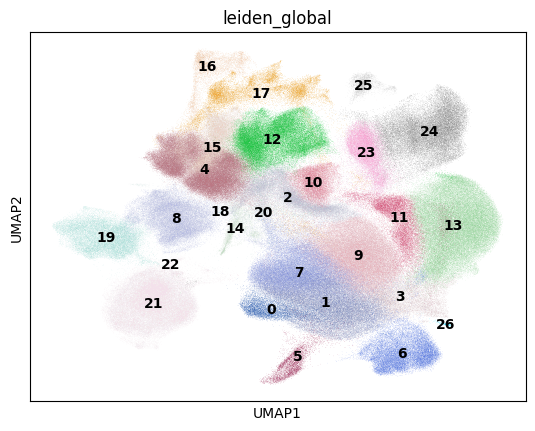

In [31]:
print(adata_all_hvg.obs['leiden_global'].unique())
sc.pl.umap(adata_all_hvg, color='leiden_global', legend_loc='on data')
adata_all.obs["leiden_global"] = adata_all_hvg.obs["leiden_global"]

In [32]:
adata_all.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,therapy,autoantibodies,seurat_clusters,cell_type_merged,cell_state,cell_state_short,leiden_r2_cellannot_SYNOVIUM,orig_index,tissue,leiden_global
0,214,SC109SSCUP,347.0,214,25.072047,16.138329,0.000000,0.000000,1.621495,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung,0
1,1814,SC109SSCUP,6536.0,1814,4.345165,22.995716,0.000000,0.000000,3.603087,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung,12
2,3219,SC109SSCUP,19483.0,3219,7.042037,12.369758,0.010265,0.000000,6.052501,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung,12
3,888,SC109SSCUP,2937.0,888,9.635682,2.110998,0.000000,0.000000,3.307432,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung,17
4,683,SC109SSCUP,1194.0,683,0.753769,2.093802,0.000000,0.000000,1.748170,GSE128169,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,lung,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SB-095_TTTGGTTAGCACTCTA-1-GSE00000,5773,SB-095,25481.0,5773,4.528864,4.674071,0.039245,0.000000,4.413823,GSE00000,...,no therapy,RNA pol III,2.0,Macrophages,M1:_MERTK+_SELENOP+_macrophages,M1,3,SB-095_TTTGGTTAGCACTCTA-1-GSE00000,synovium,12
SB-095_TTTGGTTGTCGTGATT-1-GSE00000,5180,SB-095,20068.0,5180,8.217062,17.002192,0.004983,0.014949,3.874131,GSE00000,...,no therapy,RNA pol III,0.0,Endothelial cells,E1:_ICAM1+_venous,E1,2,SB-095_TTTGGTTGTCGTGATT-1-GSE00000,synovium,8
SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,6922,SB-095,45053.0,6922,6.740949,7.613256,0.002220,0.000000,6.508668,GSE00000,...,no therapy,RNA pol III,0.0,Macrophages,M0:_MERTK+_TIMD4+_macrophages,M0,22,SB-095_TTTGGTTGTGTCCGTG-1-GSE00000,synovium,15
SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,4866,SB-095,20985.0,4866,5.127472,7.719800,0.009531,0.000000,4.312577,GSE00000,...,no therapy,RNA pol III,1.0,Macrophages,M1:_MERTK+_SELENOP+_macrophages,M1,10,SB-095_TTTGTTGAGGCGAAGG-1-GSE00000,synovium,12


In [33]:
adata_all.obs["Condition"] = adata_all.obs["Condition"].str.replace("CONTROL", "CTRL")

# Verifica
print(adata_all.obs["Condition"].value_counts())

Condition
SSC     488277
CTRL    147621
Name: count, dtype: int64


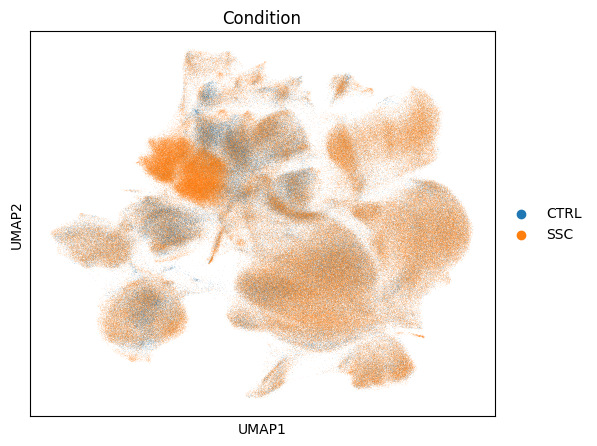

In [34]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 5)  # larghezza, altezza in pollici
sc.pl.umap(adata_all, color=['Condition'])

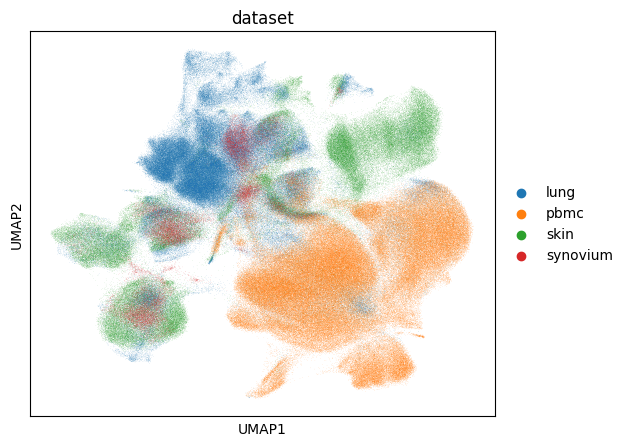

In [35]:
sc.pl.umap(adata_all, color=['dataset'])

In [36]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 5000
groupby = "leiden_global"

# Usa indici numerici invece dei nomi dei barcodes
subsampled_idx = []

for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():
    # Converti i nomi in posizioni numeriche
    positions = np.where(adata_all.obs.index.isin(indices))[0]
    n_cells = len(positions)
    
    if n_cells <= min_keep:
        chosen = positions
    else:
        chosen = np.random.choice(positions, size=min_keep, replace=False)
    
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Usa iloc-style indexing con indici numerici
adata_sub = adata_all[np.array(subsampled_idx), :].copy()

print(f"\nTotal cells before: {adata_all.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")

/tmp/ipykernel_3497815/252587823.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():


0                    → kept 5000 / 20304 cells
1                    → kept 5000 / 97443 cells
2                    → kept 5000 / 63891 cells
3                    → kept 5000 / 33380 cells
4                    → kept 5000 / 155613 cells
5                    → kept 5000 / 16035 cells
6                    → kept 5000 / 50244 cells
7                    → kept 5000 / 89099 cells
8                    → kept 5000 / 78530 cells
9                    → kept 5000 / 124559 cells
10                   → kept 5000 / 34753 cells
11                   → kept 5000 / 39724 cells
12                   → kept 5000 / 112957 cells
13                   → kept 5000 / 144952 cells
14                   → kept 5000 / 11752 cells
15                   → kept 5000 / 85146 cells
16                   → kept 5000 / 16044 cells
17                   → kept 5000 / 46130 cells
18                   → kept 66 / 66 cells
19                   → kept 5000 / 59812 cells
20                   → kept 5000 / 8139 cells
21             

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [37]:
sc.pp.log1p(adata_sub)
sc.tl.rank_genes_groups(adata_sub, groupby='leiden_global', method='wilcoxon', max_iter=500)
sc.pl.rank_genes_groups(adata_sub)

KeyboardInterrupt: 

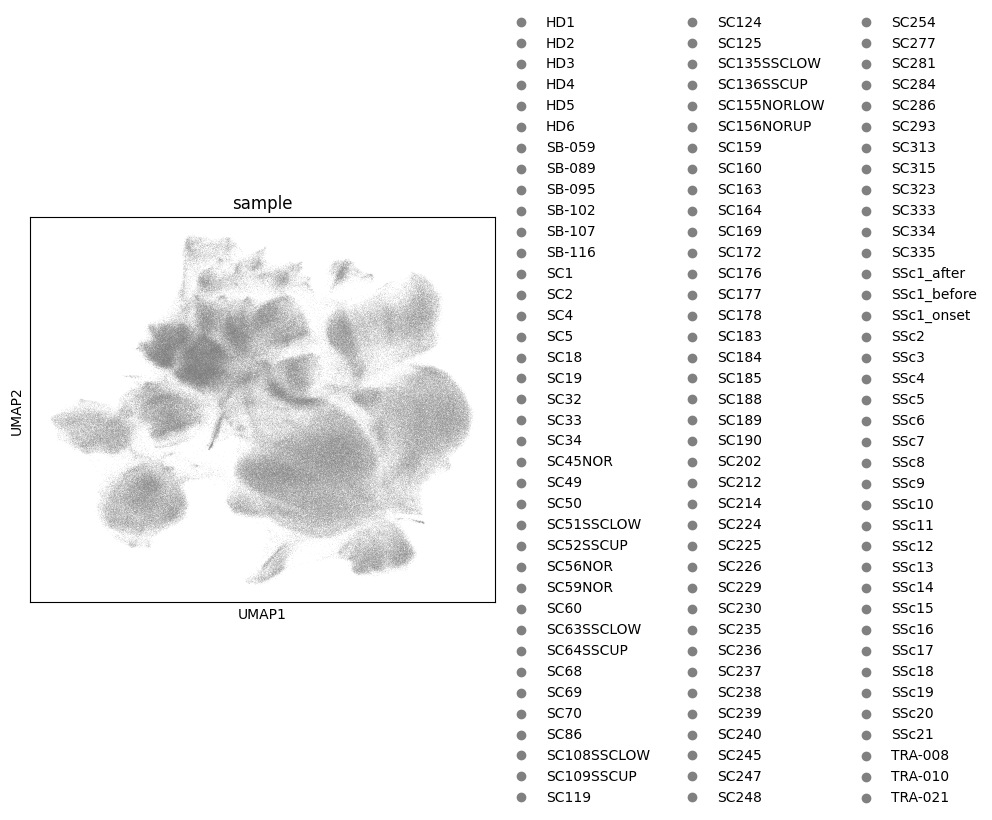

In [38]:
sc.pl.umap(adata_all, color=['sample'])

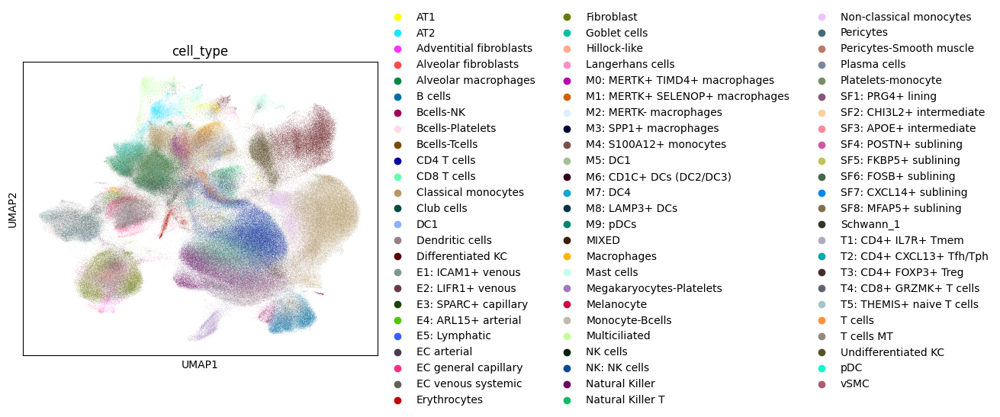

In [39]:
sc.pl.umap(adata_all, color=['cell_type'])

/tmp/ipykernel_3497815/267618849.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df.groupby(['leiden_global', 'cell_type']).size().reset_index(name='count')
/tmp/ipykernel_3497815/267618849.py:38: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


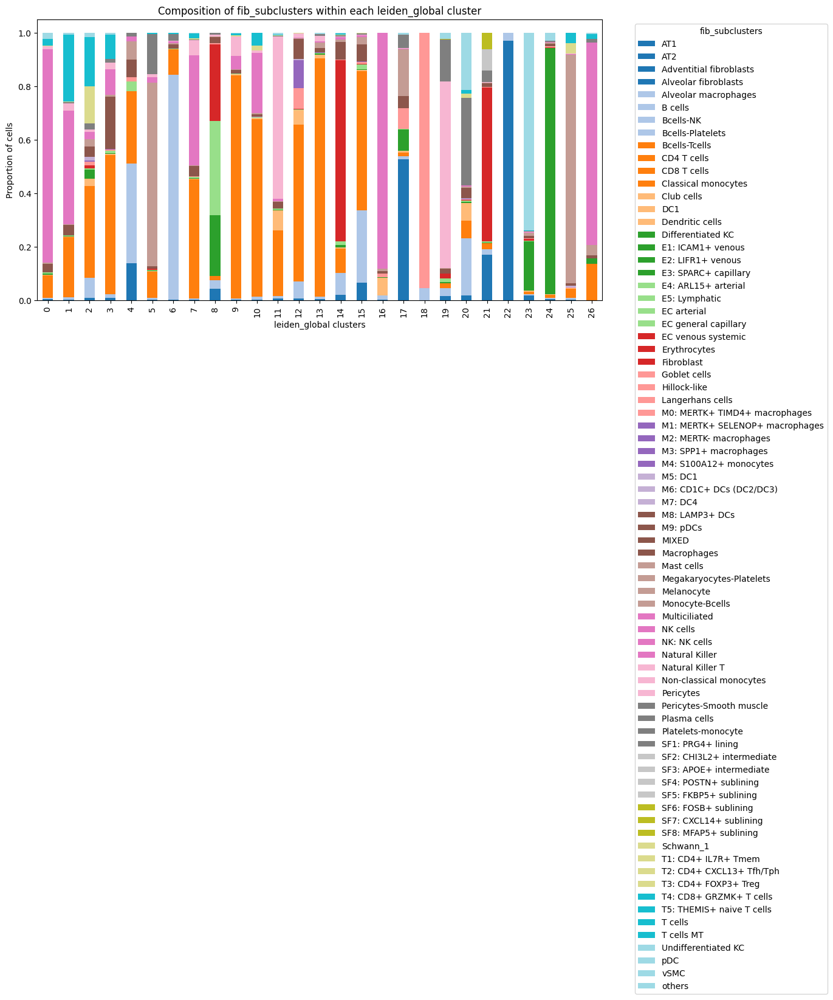

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Copy relevant columns
df = adata_all.obs[['leiden_global', 'cell_type']].copy()

# Ensure 'fib_subclusters' is categorical
df['cell_type'] = df['cell_type'].astype('category')

# Add 'others' to the categories
df['cell_type'] = df['cell_type'].cat.add_categories('others')

# Fill missing values with 'others'
df['cell_type'] = df['cell_type'].fillna('others')

# Compute counts per cluster
counts = df.groupby(['leiden_global', 'cell_type']).size().reset_index(name='count')

# Pivot for stacked bar plot
counts_pivot = counts.pivot(index='leiden_global', columns='cell_type', values='count').fillna(0)

# Optional: convert to proportions
counts_prop = counts_pivot.div(counts_pivot.sum(axis=1), axis=0)

# Plot
counts_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    colormap='tab20'
)

plt.ylabel('Proportion of cells')
plt.xlabel('leiden_global clusters')
plt.title('Composition of fib_subclusters within each leiden_global cluster')
plt.legend(title='fib_subclusters', bbox_to_anchor=(1.05,1), loc='upper left')
plt.tight_layout()
plt.show()


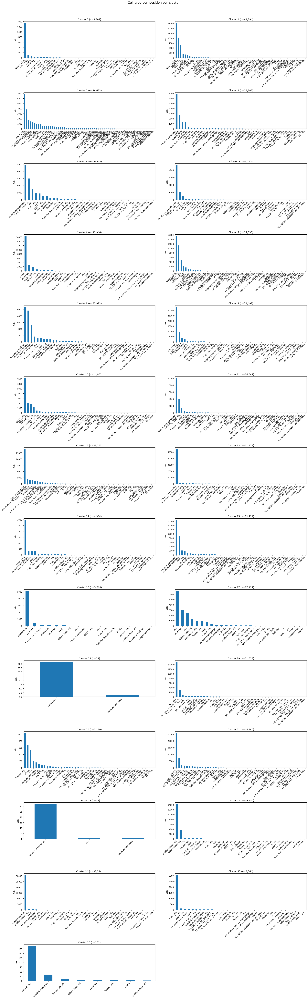

In [41]:
import math

clusters = sorted(df['leiden_global'].unique(), key=lambda x: int(x))
n = len(clusters)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 11, nrows * 5))
axes = axes.flatten()

for i, cluster in enumerate(clusters):
    df_c = df[df['leiden_global'] == cluster]
    counts_c = df_c['cell_type'].value_counts()
    counts_c = counts_c[counts_c > 0]

    counts_c.plot(kind='bar', ax=axes[i], colormap='tab20')
    axes[i].set_title(f'Cluster {cluster} (n={len(df_c):,})')
    axes[i].set_ylabel('Cells')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    for label in axes[i].get_xticklabels():
        label.set_ha('right')  # allinea a destra

# Nascondi subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Cell type composition per cluster', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

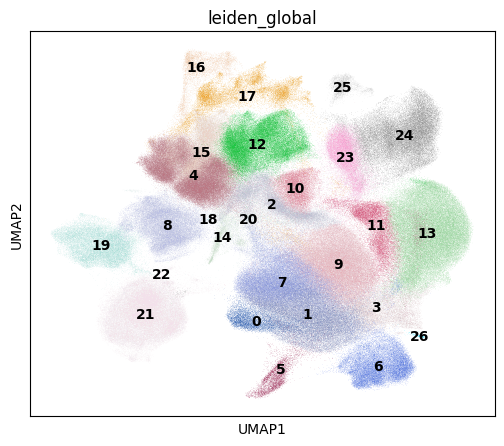

In [42]:
sc.pl.umap(adata_all, color='leiden_global', legend_loc='on data')

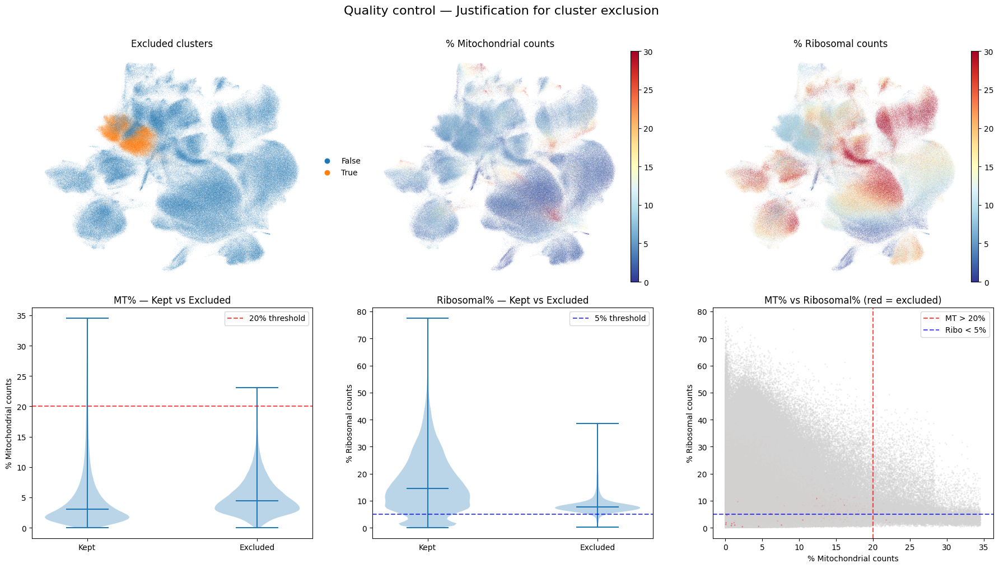

── MT% ──────────────────────────────────────
  Kept     — median: 3.0%  mean: 4.8%
  Excluded — median: 4.4%  mean: 5.1%

── Ribosomal% ───────────────────────────────
  Kept     — median: 14.6%  mean: 16.5%
  Excluded — median: 7.7%  mean: 8.3%


In [57]:
import matplotlib.pyplot as plt
import numpy as np

# Crea colonna per identificare i cluster esclusi
excluded_clusters = ["4"] #22 reincluded because multiciliated and ngenexcell > 300
adata_all.obs["excluded"] = adata_all.obs["leiden_global"].isin(excluded_clusters)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# ── PLOT 1: UMAP colorato per cluster esclusi/mantenuti ──────────────────────
sc.pl.umap(
    adata_all,
    color="excluded",
    ax=axes[0, 0],
    show=False,
    frameon=False,
    title="Excluded clusters",
)

# ── PLOT 2: UMAP % mitocondriale ─────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_mt",
    ax=axes[0, 1],
    show=False,
    frameon=False,
    title="% Mitochondrial counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── PLOT 3: UMAP % ribosomiale ───────────────────────────────────────────────
sc.pl.umap(
    adata_all,
    color="pct_counts_ribosomal",
    ax=axes[0, 2],
    show=False,
    frameon=False,
    title="% Ribosomal counts",
    cmap="RdYlBu_r",
    vmin=0,
    vmax=30,
)

# ── PLOT 4: Violin % MT per esclusi vs mantenuti ─────────────────────────────
excluded_mt   = adata_all.obs.loc[adata_all.obs["excluded"], "pct_counts_mt"]
kept_mt       = adata_all.obs.loc[~adata_all.obs["excluded"], "pct_counts_mt"]

axes[1, 0].violinplot([kept_mt, excluded_mt], positions=[0, 1], showmedians=True)
axes[1, 0].axhline(y=20, color="red", linestyle="--", alpha=0.7, label="20% threshold")
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(["Kept", "Excluded"])
axes[1, 0].set_ylabel("% Mitochondrial counts")
axes[1, 0].set_title("MT% — Kept vs Excluded")
axes[1, 0].legend()

# ── PLOT 5: Violin % Ribosomal per esclusi vs mantenuti ──────────────────────
excluded_rb = adata_all.obs.loc[adata_all.obs["excluded"], "pct_counts_ribosomal"]
kept_rb     = adata_all.obs.loc[~adata_all.obs["excluded"], "pct_counts_ribosomal"]

axes[1, 1].violinplot([kept_rb, excluded_rb], positions=[0, 1], showmedians=True)
axes[1, 1].axhline(y=5, color="blue", linestyle="--", alpha=0.7, label="5% threshold")
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(["Kept", "Excluded"])
axes[1, 1].set_ylabel("% Ribosomal counts")
axes[1, 1].set_title("Ribosomal% — Kept vs Excluded")
axes[1, 1].legend()

# ── PLOT 6: Scatter MT vs Ribosomal colorato per esclusi/mantenuti ───────────
colors = adata_all.obs["excluded"].map({True: "red", False: "lightgrey"})
axes[1, 2].scatter(
    adata_all.obs["pct_counts_mt"],
    adata_all.obs["pct_counts_ribosomal"],
    c=colors, s=1, alpha=0.3
)
axes[1, 2].axvline(x=20, color="red",  linestyle="--", alpha=0.7, label="MT > 20%")
axes[1, 2].axhline(y=5,  color="blue", linestyle="--", alpha=0.7, label="Ribo < 5%")
axes[1, 2].set_xlabel("% Mitochondrial counts")
axes[1, 2].set_ylabel("% Ribosomal counts")
axes[1, 2].set_title("MT% vs Ribosomal% (red = excluded)")
axes[1, 2].legend()

plt.suptitle("Quality control — Justification for cluster exclusion", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig("qc_exclusion_justification.png", dpi=150, bbox_inches="tight")
plt.show()

# ── SUMMARY STATISTICO ────────────────────────────────────────────────────────
print("── MT% ──────────────────────────────────────")
print(f"  Kept     — median: {kept_mt.median():.1f}%  mean: {kept_mt.mean():.1f}%")
print(f"  Excluded — median: {excluded_mt.median():.1f}%  mean: {excluded_mt.mean():.1f}%")
print("\n── Ribosomal% ───────────────────────────────")
print(f"  Kept     — median: {kept_rb.median():.1f}%  mean: {kept_rb.mean():.1f}%")
print(f"  Excluded — median: {excluded_rb.median():.1f}%  mean: {excluded_rb.mean():.1f}%")

Ambient genes trovati: 13/13


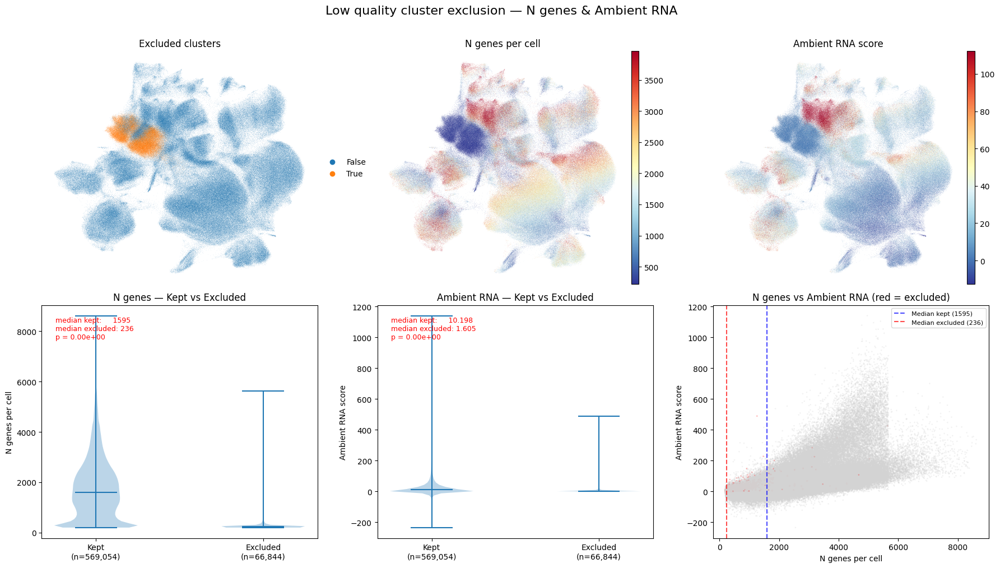


── Statistiche per cluster escluso ──────────────────────────────
Cluster     N cells  Median n_genes  Median ambient Top samples
---------------------------------------------------------------------------
4            66,844             236           1.605 SC284, SC281


In [58]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# ── GENE SIGNATURES ──────────────────────────────────────────────────────────
# Ambient RNA / housekeeping genes — highly expressed in empty droplets
ambient_genes = [
    "MALAT1", "NEAT1",                          # lncRNA ubiqui nell'ambient RNA
    "ACTB", "ACTG1",                            # actina
    "GAPDH", "LDHA",                            # glicolisi
    "B2M",                                      # MHC I ubiquo
    "FTL", "FTH1",                              # ferritina — molto abbondante
    "TMSB4X", "TMSB10",                         # thymosine — ambient marker
    "S100A4", "VIM",                            # proteine strutturali ubique
]

ambient_present = [g for g in ambient_genes if g in adata_all.var_names]
missing = [g for g in ambient_genes if g not in adata_all.var_names]
print(f"Ambient genes trovati: {len(ambient_present)}/{len(ambient_genes)}")
if missing:
    print(f"Mancanti: {missing}")

sc.tl.score_genes(adata_all, ambient_present, score_name="ambient_score")

# ── FIGURE ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# ── UMAP: cluster esclusi ─────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="excluded",
           ax=axes[0, 0], show=False, frameon=False,
           title="Excluded clusters")

# ── UMAP: n_genes ─────────────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="n_genes",
           ax=axes[0, 1], show=False, frameon=False,
           title="N genes per cell",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["n_genes"].quantile(0.05),
           vmax=adata_all.obs["n_genes"].quantile(0.95))

# ── UMAP: ambient score ───────────────────────────────────────────────────────
sc.pl.umap(adata_all, color="ambient_score",
           ax=axes[0, 2], show=False, frameon=False,
           title="Ambient RNA score",
           cmap="RdYlBu_r",
           vmin=adata_all.obs["ambient_score"].quantile(0.05),
           vmax=adata_all.obs["ambient_score"].quantile(0.95))

# ── VIOLIN: n_genes kept vs excluded ─────────────────────────────────────────
kept_ng     = adata_all.obs.loc[~adata_all.obs["excluded"], "n_genes"]
excluded_ng = adata_all.obs.loc[adata_all.obs["excluded"],  "n_genes"]

axes[1, 0].violinplot([kept_ng, excluded_ng], positions=[0, 1], showmedians=True)
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels([f"Kept\n(n={len(kept_ng):,})", 
                              f"Excluded\n(n={len(excluded_ng):,})"])
axes[1, 0].set_ylabel("N genes per cell")
axes[1, 0].set_title("N genes — Kept vs Excluded")
stat, pval = stats.mannwhitneyu(kept_ng, excluded_ng, alternative="two-sided")
axes[1, 0].text(0.05, 0.95, 
                f"median kept:     {kept_ng.median():.0f}\n"
                f"median excluded: {excluded_ng.median():.0f}\n"
                f"p = {pval:.2e}",
                transform=axes[1, 0].transAxes,
                fontsize=9, color="red", va="top")

# ── VIOLIN: ambient score kept vs excluded ────────────────────────────────────
kept_amb     = adata_all.obs.loc[~adata_all.obs["excluded"], "ambient_score"]
excluded_amb = adata_all.obs.loc[adata_all.obs["excluded"],  "ambient_score"]

axes[1, 1].violinplot([kept_amb, excluded_amb], positions=[0, 1], showmedians=True)
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels([f"Kept\n(n={len(kept_amb):,})",
                              f"Excluded\n(n={len(excluded_amb):,})"])
axes[1, 1].set_ylabel("Ambient RNA score")
axes[1, 1].set_title("Ambient RNA — Kept vs Excluded")
stat, pval = stats.mannwhitneyu(kept_amb, excluded_amb, alternative="two-sided")
axes[1, 1].text(0.05, 0.95,
                f"median kept:     {kept_amb.median():.3f}\n"
                f"median excluded: {excluded_amb.median():.3f}\n"
                f"p = {pval:.2e}",
                transform=axes[1, 1].transAxes,
                fontsize=9, color="red", va="top")

# ── SCATTER: n_genes vs ambient score, colorato per esclusi ──────────────────
colors = adata_all.obs["excluded"].map({True: "red", False: "lightgrey"})
axes[1, 2].scatter(
    adata_all.obs["n_genes"],
    adata_all.obs["ambient_score"],
    c=colors, s=1, alpha=0.2
)
axes[1, 2].set_xlabel("N genes per cell")
axes[1, 2].set_ylabel("Ambient RNA score")
axes[1, 2].set_title("N genes vs Ambient RNA (red = excluded)")

# Aggiungi linee mediane
axes[1, 2].axvline(x=kept_ng.median(), color="blue", linestyle="--", 
                    alpha=0.7, label=f"Median kept ({kept_ng.median():.0f})")
axes[1, 2].axvline(x=excluded_ng.median(), color="red", linestyle="--",
                    alpha=0.7, label=f"Median excluded ({excluded_ng.median():.0f})")
axes[1, 2].legend(fontsize=8)

plt.suptitle("Low quality cluster exclusion — N genes & Ambient RNA", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig("qc_ngenes_ambient_justification.png", dpi=150, bbox_inches="tight")
plt.show()

# ── SUMMARY PER CLUSTER ESCLUSO ───────────────────────────────────────────────
print("\n── Statistiche per cluster escluso ──────────────────────────────")
print(f"{'Cluster':<10} {'N cells':>8} {'Median n_genes':>15} {'Median ambient':>15} {'Top samples'}")
print("-" * 75)

excluded_clusters = ["4"]
for cl in excluded_clusters:
    mask_cl = adata_all.obs["leiden_global"] == cl
    subset  = adata_all.obs[mask_cl]
    top_samples = subset["sample"].value_counts().head(2).index.tolist()
    print(f"{cl:<10} {mask_cl.sum():>8,} "
          f"{subset['n_genes'].median():>15.0f} "
          f"{subset['ambient_score'].median():>15.3f} "
          f"{', '.join(top_samples)}")

In [62]:
import numpy as np

# Identifica cluster con pochi geni
CLUSTER_KEY = "leiden_global"  # o "louvain", "cell_group_manual", etc.
MIN_GENES = 300

print("="*60)
print("FINDING LOW-QUALITY CLUSTERS")
print("="*60)

# Calcola media n_genes per cluster
cluster_stats = adata_all.obs.groupby(CLUSTER_KEY)['n_genes_by_counts'].agg(['mean', 'count'])
cluster_stats.columns = ['mean_genes', 'n_cells']
cluster_stats = cluster_stats.sort_values('mean_genes')

# Identifica cluster sotto soglia
low_quality = cluster_stats[cluster_stats['mean_genes'] < MIN_GENES]

print(f"\n📊 Clusters with mean n_genes < {MIN_GENES}:")
print(low_quality)

print(f"\n🎯 Clusters to remove: {list(low_quality.index)}")
print(f"   Total cells to remove: {low_quality['n_cells'].sum():,}")

# Lista completa per copia-incolla
bad_clusters = list(low_quality.index)
print(f"\n📋 Copy-paste list:")
print(f"bad_clusters = {bad_clusters}")

FINDING LOW-QUALITY CLUSTERS

📊 Clusters with mean n_genes < 300:
               mean_genes  n_cells
leiden_global                     
4              253.726483    66844

🎯 Clusters to remove: ['4']
   Total cells to remove: 66,844

📋 Copy-paste list:
bad_clusters = ['4']


/tmp/ipykernel_3497815/334779767.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cluster_stats = adata_all.obs.groupby(CLUSTER_KEY)['n_genes_by_counts'].agg(['mean', 'count'])


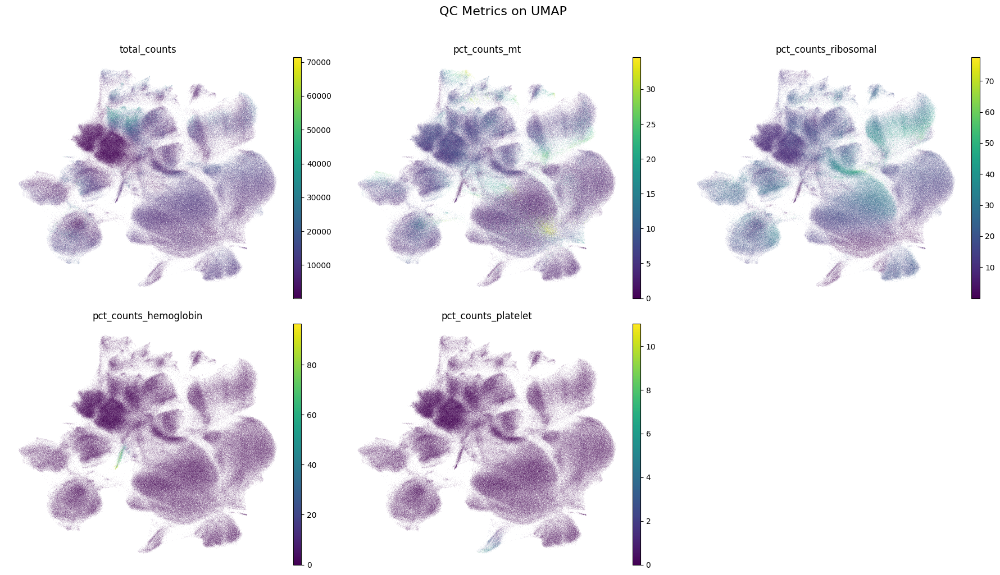

In [43]:
import matplotlib.pyplot as plt
import scanpy as sc

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

variables = ["total_counts", "pct_counts_mt", "pct_counts_ribosomal", 
             "pct_counts_hemoglobin", "pct_counts_platelet"]

for i, var in enumerate(variables):
    sc.pl.umap(
        adata_all,
        color=var,
        ax=axes[i],
        show=False,
        frameon=False,
        title=var
    )

# Rimuovi l'ultimo subplot vuoto
axes[-1].set_visible(False)

plt.suptitle("QC Metrics on UMAP", fontsize=16, y=1.02)
plt.tight_layout()

In [44]:
adata_all.obs["cell_type"].value_counts().sort_values()

cell_type
E5: Lymphatic                    15
M8: LAMP3+ DCs                   28
M5: DC1                          40
M7: DC4                          54
SF2: CHI3L2+ intermediate        71
                              ...  
Differentiated KC             37406
Alveolar macrophages          42051
Natural Killer                46476
CD4 T cells                   52849
Classical monocytes          131468
Name: count, Length: 74, dtype: int64

In [45]:
adata_all.obs["sample"].value_counts().sort_values()

sample
SB-059     1103
SC245      1149
SC230      1208
SC1        1407
SC247      1436
          ...  
SSc10     18495
SSc9      18795
SSc20     18928
SC281     41934
SC284     59580
Name: count, Length: 114, dtype: int64

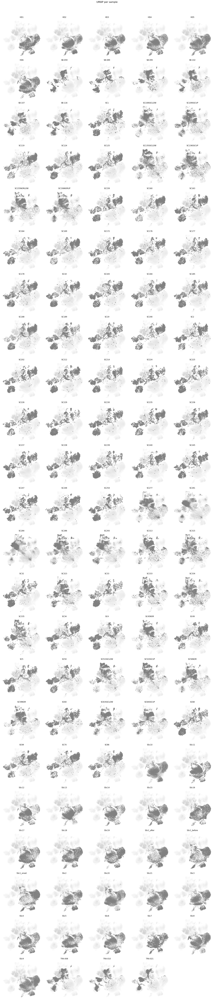

In [46]:
import matplotlib.pyplot as plt
import math

# Rimuovi NaN e converti in stringa
cell_types = sorted(adata_all.obs['sample'].dropna().astype(str).unique())
n = len(cell_types)

# Calcola griglia
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, batch in enumerate(cell_types):
    adata_batch = adata_all[adata_all.obs['sample'] == batch]
    
    sc.pl.umap(
        adata_all,          # sfondo grigio con tutte le cellule
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        na_color="lightgrey",
        alpha=0.1           # tutte le cellule in grigio trasparente
    )
    # Sovrapponi le cellule del batch in evidenza
    sc.pl.umap(
        adata_batch,
        color='sample',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        alpha=0.8
    )

# Nascondi i subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("UMAP per sample", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

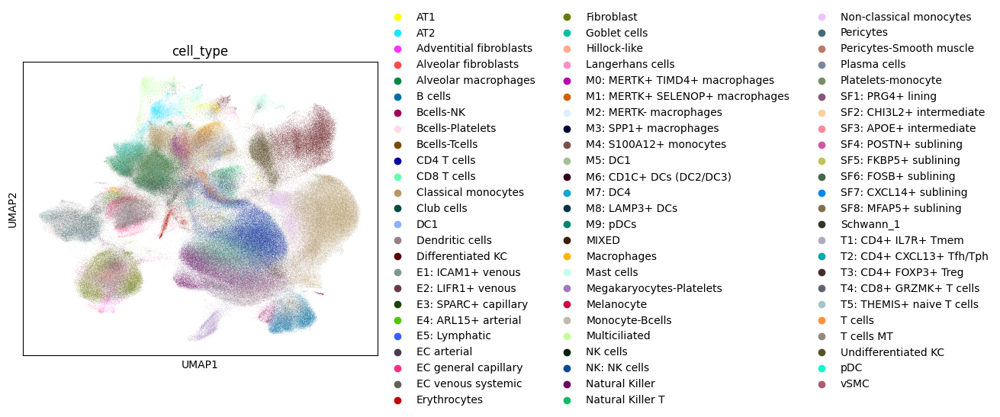

In [47]:
sc.pl.umap(adata_all, color=['cell_type'])

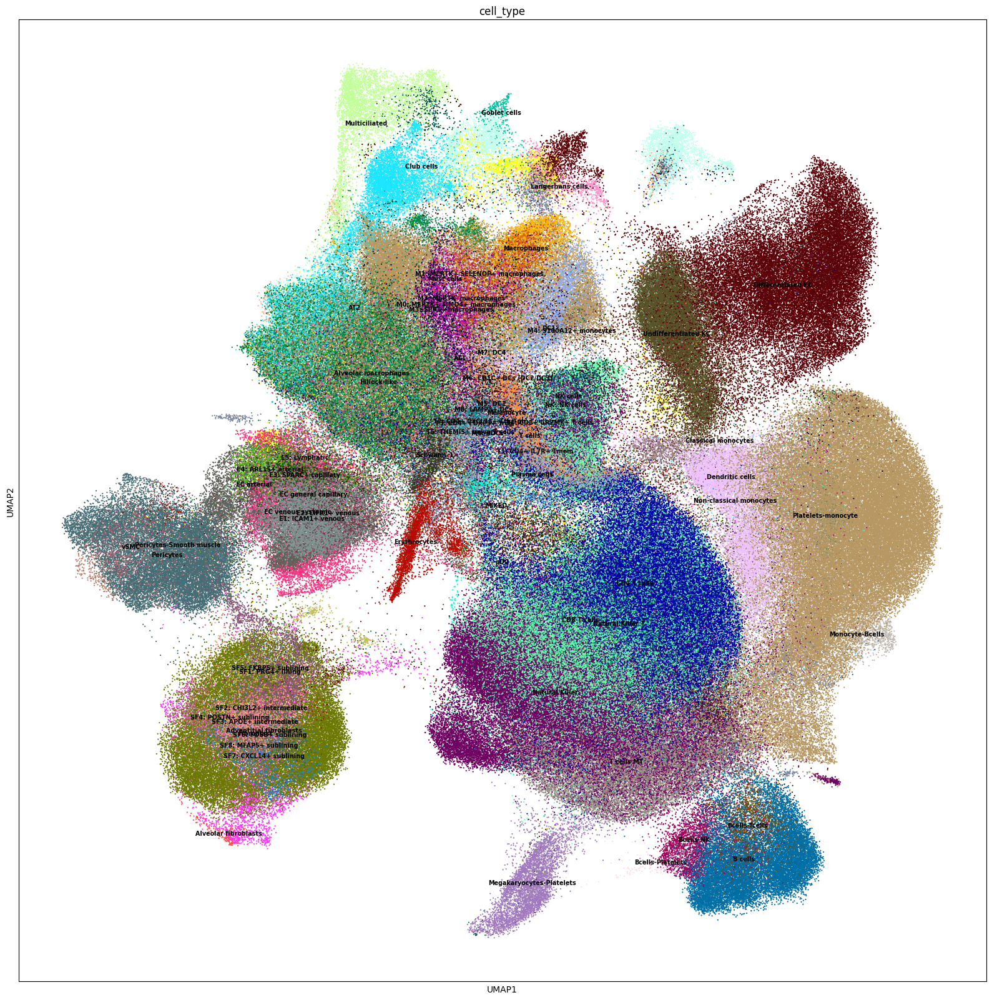

In [48]:
plt.rcParams["figure.figsize"] = (20, 20)
sc.pl.umap(adata_all, color=['cell_type'], legend_loc='on data', legend_fontsize= 'x-small',size=10)

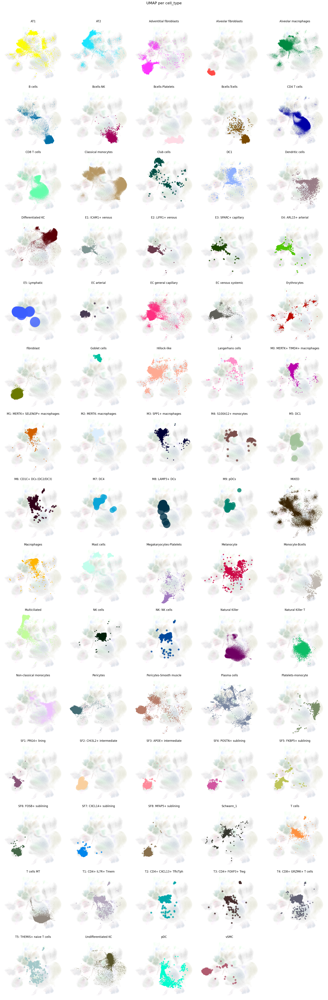

In [49]:
import matplotlib.pyplot as plt
import math

# Rimuovi NaN e converti in stringa
cell_types = sorted(adata_all.obs['cell_type'].dropna().astype(str).unique())
n = len(cell_types)

# Calcola griglia
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, batch in enumerate(cell_types):
    adata_batch = adata_all[adata_all.obs['cell_type'] == batch]
    
    sc.pl.umap(
        adata_all,          # sfondo grigio con tutte le cellule
        color='cell_type',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        na_color="lightgrey",
        alpha=0.1           # tutte le cellule in grigio trasparente
    )
    # Sovrapponi le cellule del batch in evidenza
    sc.pl.umap(
        adata_batch,
        color='cell_type',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        alpha=0.8
    )

# Nascondi i subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("UMAP per cell_type", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [50]:
import pandas as pd
pd.set_option("display.max_seq_items", None)

print(adata_all.obs["cell_type"].cat.categories.tolist())

['AT1', 'AT2', 'Adventitial fibroblasts', 'Alveolar fibroblasts', 'Alveolar macrophages', 'B cells', 'Bcells-NK', 'Bcells-Platelets', 'Bcells-Tcells', 'CD4 T cells', 'CD8 T cells', 'Classical monocytes', 'Club cells', 'DC1', 'Dendritic cells', 'Differentiated KC', 'E1: ICAM1+ venous', 'E2: LIFR1+ venous', 'E3: SPARC+ capillary', 'E4: ARL15+ arterial', 'E5: Lymphatic', 'EC arterial', 'EC general capillary', 'EC venous systemic', 'Erythrocytes', 'Fibroblast', 'Goblet cells', 'Hillock-like', 'Langerhans cells', 'M0: MERTK+ TIMD4+ macrophages', 'M1: MERTK+ SELENOP+ macrophages', 'M2: MERTK- macrophages', 'M3: SPP1+ macrophages', 'M4: S100A12+ monocytes', 'M5: DC1', 'M6: CD1C+ DCs (DC2/DC3)', 'M7: DC4', 'M8: LAMP3+ DCs', 'M9: pDCs', 'MIXED', 'Macrophages', 'Mast cells', 'Megakaryocytes-Platelets', 'Melanocyte', 'Monocyte-Bcells', 'Multiciliated', 'NK cells', 'NK: NK cells', 'Natural Killer', 'Natural Killer T', 'Non-classical monocytes', 'Pericytes', 'Pericytes-Smooth muscle', 'Plasma cells

In [51]:
cell_groups = {
    # ---------------------------
    # MONOCYTES
    # ---------------------------
    "Monocytes": [
        "Classical monocytes",
        "Non-classical monocytes",
        "Monocytes-Mph",
        "M4: S100A12+ monocytes",
    ],
    # ---------------------------
    # MACROPHAGES
    # ---------------------------
    "Macrophages": [
        "Macrophages",
        "Alveolar macrophages",
        "M0: MERTK+ TIMD4+ macrophages",
        "M1: MERTK+ SELENOP+ macrophages",
        "M2: MERTK- macrophages",
        "M3: SPP1+ macrophages",
    ],
    # ---------------------------
    # DENDRITIC CELLS
    # ---------------------------
    "Dendritic_cells": [
        "DC1",
        "Dendritic cells",
        "Langerhans cells",
        "pDC",
        "M5: DC1",
        "M6: CD1C+ DCs (DC2/DC3)",
        "M7: DC4",
        "M8: LAMP3+ DCs",
        "M9: pDCs",
        "DC2"
    ],
    # ---------------------------
    # T CELLS
    # ---------------------------
    "T_cells": [
        "T cells",
        "T cells MT",
        "CD4 T cells",
        "CD8 T cells",
        "CD4 T cellse",
        "Natural Killer T",
        "T1: CD4+ IL7R+ Tmem",
        "T2: CD4+ CXCL13+ Tfh/Tph",
        "T3: CD4+ FOXP3+ Treg",
        "T4: CD8+ GRZMK+ T cells",
        "T5: THEMIS+ naive T cells",
    ],
    # ---------------------------
    # NK / ILC
    # ---------------------------
    "NK_ILC": [
        "NK cells",
        "Natural Killer",
        "NK: NK cells",
    ],
    # ---------------------------
    # B CELLS
    # ---------------------------
    "B_cells": [
        "B cells",
    ],
    # ---------------------------
    # PLASMA CELLS
    # ---------------------------
    "Plasma_cells": [
        "Plasma cells",
    ],
    # ---------------------------
    # ENDOTHELIAL
    # ---------------------------
    "Endothelial": [
        "EC arterial",
        "EC general capillary",
        "EC venous systemic",
        "Lymphatic EC",
        "E1: ICAM1+ venous",
        "E2: LIFR1+ venous",
        "E3: SPARC+ capillary",
        "E4: ARL15+ arterial",
        "E5: Lymphatic",
    ],
    # ---------------------------
    # FIBROBLASTS
    # ---------------------------
    "Fibroblasts": [
        "Fibroblast",
        "Adventitial fibroblasts",
        "Alveolar fibroblasts",
        "SF1: PRG4+ lining",
        "SF2: CHI3L2+ intermediate",
        "SF3: APOE+ intermediate",
        "SF4: POSTN+ sublining",
        "SF5: FKBP5+ sublining",
        "SF6: FOSB+ sublining",
        "SF7: CXCL14+ sublining",
        "SF8: MFAP5+ sublining",
    ],
    # ---------------------------
    # EPITHELIAL
    # ---------------------------
    "Epithelial": [
        "AT1",
        "AT2",
        "Club cells",
        "Goblet cells",
        "Multiciliated",
        "Hillock-like",
        "Undifferentiated KC",
        "Differentiated KC",
    ],
    # ---------------------------
    # PERICYTES
    # ---------------------------
    "Pericytes": [
        "Pericytes",
        "Pericytes-Smooth muscle",
    ],
    # ---------------------------
    # SMOOTH MUSCLE
    # ---------------------------
    "Smooth_muscle": [
        "vSMC",
    ],
    # ---------------------------
    # MAST CELLS
    # ---------------------------
    "Mast_cells": [
        "Mast cells",
    ],
    # ---------------------------
    # STROMAL MISC
    # ---------------------------
    "Stromal_misc": [
        "Melanocyte",
        "Schwann_1",
    ],
    # ---------------------------
    # DOUBLETS / CONTAMINATION
    # ---------------------------
    "Doublets_contamination": [
        "Bcells-NK",
        "Bcells-Platelets",
        "Bcells-Tcells",
        "Monocyte-Bcells",
        "Platelets-monocyte",
        "Megakaryocytes-Platelets",
        "Erythrocytes",
        "NK cells-CD8 T cells",
        "MIXED",
        
    ],
}

# Crea colonna
adata_all.obs["cell_group"] = "Other"

# Assegna gruppi
for group, members in cell_groups.items():
    adata_all.obs.loc[adata_all.obs["cell_type"].isin(members), "cell_group"] = group

    
# Verifica
print(adata_all.obs["cell_group"].value_counts())
n_other = (adata_all.obs["cell_group"] == "Other").sum()
if n_other > 0:
    print(f"\n⚠️ {n_other} cellule non mappate:")
    print(adata_all.obs[adata_all.obs["cell_group"] == "Other"]["cell_type"].value_counts())
else:
    print("\n✅ Tutte le cellule mappate correttamente!")


cell_group
Monocytes                 145007
T_cells                   119320
Epithelial                 87927
Macrophages                54156
NK_ILC                     48334
Fibroblasts                42792
Doublets_contamination     36218
Endothelial                34684
Pericytes                  19964
B_cells                    18902
Mast_cells                 12374
Dendritic_cells             9183
Plasma_cells                4378
Stromal_misc                2166
Smooth_muscle                493
Name: count, dtype: int64

✅ Tutte le cellule mappate correttamente!


INTEGRATION QC CHECKS - IMPROVED

[*] Creating batch→tissue mapping...
  Batch → Tissue mapping:
    E-GEAD-872      → pbmc
    GSE00000        → synovium
    GSE128169       → lung
    GSE138669       → skin
    GSE209635       → skin
    GSE212109       → lung

  Tissues found: ['lung', 'pbmc', 'skin', 'synovium']
  Color scheme assigned

  Batch order (grouped by tissue):
    GSE128169       (lung)
    GSE212109       (lung)
    E-GEAD-872      (pbmc)
    GSE138669       (skin)
    GSE209635       (skin)
    GSE00000        (synovium)

[5/9] Validating marker gene expression...

  Marker gene consistency check:
  (Should be similar expression across batches for same cell type)

  gene     cv_pct status
  KRT8 110.301758      🚨
 EPCAM 107.352135      🚨
  CD19  89.755836     ⚠️
 TPSB2  78.866234     ⚠️
 CD163  76.191811     ⚠️
TPSAB1  74.473503     ⚠️
 MS4A1  71.372726     ⚠️
JCHAIN  68.116676     ⚠️
  MZB1  64.305702     ⚠️
PDGFRA  63.884716     ⚠️
   CD4  61.986034     ⚠️
 ITGAX  60

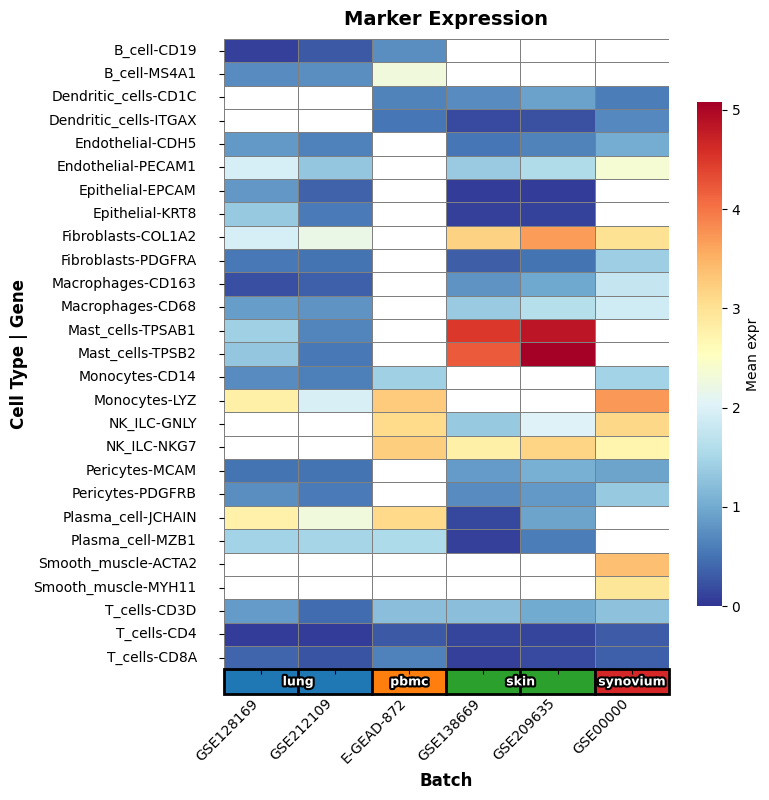

In [55]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import seaborn as sns
from scipy import stats
from sklearn.metrics import silhouette_score

# ═══════════════════════════════════════════════════════════
# CONFIGURAZIONE
# ═══════════════════════════════════════════════════════════

# Marker genes canonici per validazione (ridotti per chiarezza)
MARKER_GENES = {
    "Monocytes": ["CD14", "LYZ"],
    "Macrophages": ["CD68", "CD163"],
    "Dendritic_cells": ["CD1C", "ITGAX"],
    "T_cells": ["CD3D", "CD4", "CD8A"],
    "NK_ILC": ["NKG7", "GNLY"],
    "B_cell": ["MS4A1", "CD19"],
    "Plasma_cell": ["JCHAIN", "MZB1"],
    "Endothelial": ["PECAM1", "CDH5"],
    "Fibroblasts": ["COL1A2", "PDGFRA"],
    "Epithelial": ["EPCAM", "KRT8"],
    "Pericytes": ["PDGFRB", "MCAM"],
    "Smooth_muscle": ["ACTA2", "MYH11"],
    "Mast_cells": ["TPSAB1", "TPSB2"],
}

# Colonne metadata importanti
BATCH_KEY = "batch"
TISSUE_KEY = "tissue"
CELLTYPE_KEY = "cell_group"
CONDITION_KEY = "Condition"

print("="*70)
print("INTEGRATION QC CHECKS - IMPROVED")
print("="*70)


# ═══════════════════════════════════════════════════════════
# CREATE BATCH→TISSUE MAPPING & COLOR SCHEME
# ═══════════════════════════════════════════════════════════

print("\n[*] Creating batch→tissue mapping...")

# Create mapping
batch_to_tissue = adata_all.obs[[BATCH_KEY, TISSUE_KEY]].drop_duplicates().set_index(BATCH_KEY)[TISSUE_KEY].to_dict()

print("  Batch → Tissue mapping:")
for batch, tissue in sorted(batch_to_tissue.items()):
    print(f"    {batch:15s} → {tissue}")

# Get unique tissues and assign colors
unique_tissues = sorted(set(batch_to_tissue.values()))
tissue_colors = sns.color_palette("tab10", n_colors=len(unique_tissues))
tissue_to_color = dict(zip(unique_tissues, tissue_colors))

print(f"\n  Tissues found: {unique_tissues}")
print(f"  Color scheme assigned")

# ORDER BATCHES BY TISSUE (batches from same tissue grouped together)
# This makes plots more readable
batches_grouped_by_tissue = []
for tissue in sorted(unique_tissues):
    batches_in_tissue = [b for b, t in batch_to_tissue.items() if t == tissue]
    batches_grouped_by_tissue.extend(sorted(batches_in_tissue))

batches_ordered = batches_grouped_by_tissue  # Use tissue-ordered list

print(f"\n  Batch order (grouped by tissue):")
for batch in batches_ordered:
    print(f"    {batch:15s} ({batch_to_tissue[batch]})")

# Create batch color list (ordered by tissue grouping)
batch_colors = [tissue_to_color[batch_to_tissue[b]] for b in batches_ordered]


# ═══════════════════════════════════════════════════════════
# TEST 4: MARKER GENE EXPRESSION CROSS-BATCH
# ═══════════════════════════════════════════════════════════

print("\n[5/9] Validating marker gene expression...")

marker_results = []

for celltype, genes in MARKER_GENES.items():
    # Check if cell type exists
    if not adata_all.obs[CELLTYPE_KEY].str.contains(celltype, case=False, na=False).any():
        continue
    
    # Get cells of this type
    mask = adata_all.obs[CELLTYPE_KEY].str.contains(celltype, case=False, na=False)
    
    for gene in genes:
        if gene not in adata_all.var_names:
            continue
        
        # Expression per batch for this cell type
        for batch in batches_ordered:
            batch_mask = mask & (adata_all.obs[BATCH_KEY] == batch)
            
            if batch_mask.sum() == 0:
                continue
            
            adata_subset = adata_all[batch_mask]
            expr = adata_subset[:, gene].X
            
            if hasattr(expr, 'toarray'):
                expr = expr.toarray().flatten()
            else:
                expr = np.array(expr).flatten()
            
            marker_results.append({
                'cell_group': celltype,
                'gene': gene,
                'batch': batch,
                'tissue': batch_to_tissue[batch],
                'mean_expr': expr.mean(),
                'pct_expressing': (expr > 0).sum() / len(expr) * 100,
                'n_cells': len(expr)
            })

if marker_results:
    marker_df = pd.DataFrame(marker_results)
    
    print("\n  Marker gene consistency check:")
    print("  (Should be similar expression across batches for same cell type)\n")
    
    # For each gene, check CV across batches
    consistency_check = []
    for gene in marker_df['gene'].unique():
        gene_data = marker_df[marker_df['gene'] == gene]
        
        if len(gene_data) > 1:
            cv = gene_data['mean_expr'].std() / gene_data['mean_expr'].mean() * 100
            consistency_check.append({
                'gene': gene,
                'cv_pct': cv,
                'status': '✓' if cv < 50 else '⚠️' if cv < 100 else '🚨'
            })
    
    consistency_df = pd.DataFrame(consistency_check).sort_values('cv_pct', ascending=False)
    print(consistency_df.head(15).to_string(index=False))
    
    if (consistency_df['cv_pct'] > 100).any():
        print("\n  🚨 WARNING: Some markers have >100% CV across batches!")
        print("     → Expression not consistent - check normalization")
    else:
        print("\n  ✓ Marker genes reasonably consistent")
    
    # Create pivot table for heatmap
    pivot = marker_df.pivot_table(
        values='mean_expr', 
        index=['cell_group', 'gene'], 
        columns='batch'
    )
    
    # Plot heatmap with tissue annotation - OPTIMIZED FOR MINIATURIZATION
    # Reorder columns by tissue
    pivot = pivot[batches_ordered]  # Use tissue-ordered batches
    
    if not pivot.empty:
        # Compact figure size
        n_batches = len(batches_ordered)
        n_markers = len(pivot)
        fig_width = min(12, max(8, n_batches * 0.6))
        fig_height = min(10, max(6, n_markers * 0.3))
        
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))
        
        # Heatmap - NO ANNOTATIONS if too many cells (unreadable when small)
        show_annot = (n_batches * n_markers) < 120  # Only annotate if <120 cells
        
        sns.heatmap(pivot, 
                    annot=show_annot,  # Conditional annotations
                    fmt='.1f' if show_annot else '',  # 1 decimal if annotating
                    cmap='RdYlBu_r', 
                    ax=ax,
                    linewidths=0.5,
                    linecolor='gray',
                    cbar_kws={'label': 'Mean expr', 'shrink': 0.8},
                    vmin=0,
                    vmax=None)
        
        # Title - LARGER, more concise
        ax.set_title('Marker Expression', fontsize=14, fontweight='bold', pad=10)
        
        # Labels - LARGER FONTS
        ax.set_xlabel('Batch', fontsize=12, fontweight='bold')
        ax.set_ylabel('Cell Type | Gene', fontsize=12, fontweight='bold')
        
        # Tick labels - LARGER
        ax.tick_params(axis='both', labelsize=10, pad=16)
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        
        # Add tissue color bar on top
        tissue_row = [batch_to_tissue[b] for b in pivot.columns]
        tissue_colors_ordered = [tissue_to_color[t] for t in tissue_row]
        
        # Colored rectangles at top (tissue indicator) - TALLER BAR
        y_top = len(pivot)
        bar_height = max(0.8, len(pivot) * 0.04)  # MOLTO PIÙ ALTA (era 0.4 e 0.02)
        
        for i, (batch, color) in enumerate(zip(pivot.columns, tissue_colors_ordered)):
            ax.add_patch(plt.Rectangle((i, y_top), 1, bar_height, 
                                       facecolor=color, edgecolor='black', 
                                       linewidth=2.0, clip_on=False))  # Bordo più spesso
        
        # Add tissue labels on color bar - LARGER FONT
        prev_tissue = None
        for i, (batch, tissue) in enumerate(zip(pivot.columns, tissue_row)):
            if tissue != prev_tissue:
                # Find center of this tissue's span
                tissue_batches = [b for b in pivot.columns if batch_to_tissue[b] == tissue]
                start_idx = list(pivot.columns).index(tissue_batches[0])
                end_idx = list(pivot.columns).index(tissue_batches[-1])
                center = (start_idx + end_idx + 1) / 2
                
                # TESTO PIÙ GRANDE - direttamente sul box colorato
                ax.text(center, y_top + bar_height/2, tissue, 
                       ha='center', va='center', 
                       fontsize=9,  # Era 9, ora 13 (molto più grande)
                       fontweight='bold',
                       color='white',  # Bianco su sfondo colorato
                       path_effects=[
                           path_effects.withStroke(linewidth=3, foreground='black')
                       ])  # Outline nero per massima leggibilità
            prev_tissue = tissue
        
        # Tight layout
        plt.tight_layout()
        #plt.savefig('qc_3_marker_genes.png', dpi=300, bbox_inches='tight',
                    #facecolor='white', edgecolor='none', pad_inches=0.1)
        print("  → Saved: qc_3_marker_genes.png")
        if not show_annot:
            print("     (Annotations hidden - too many cells for readability when miniaturized)")
        #plt.close()



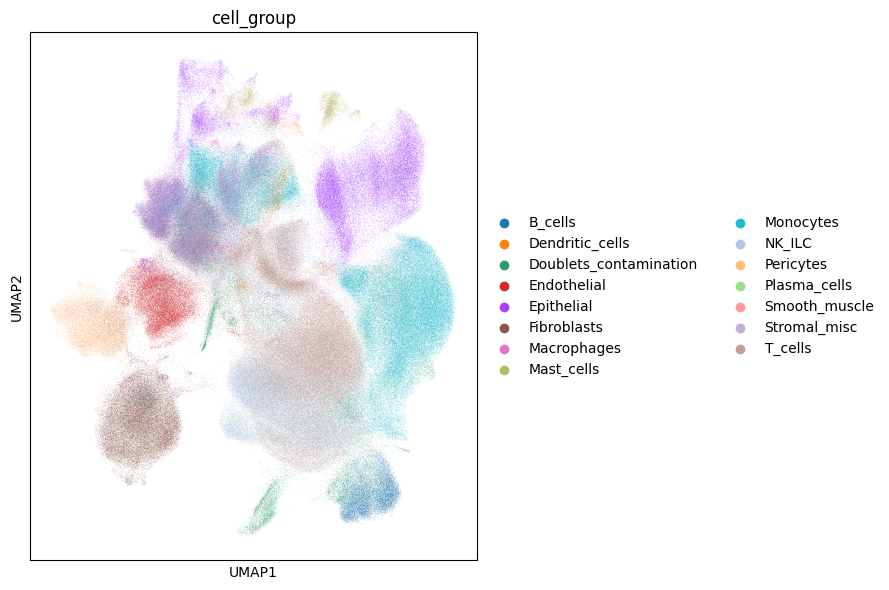

In [53]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(9, 6))
sc.pl.umap(
    adata_all, 
    color='cell_group', 
    ax=ax,
    show=False
)
plt.tight_layout()
plt.show()

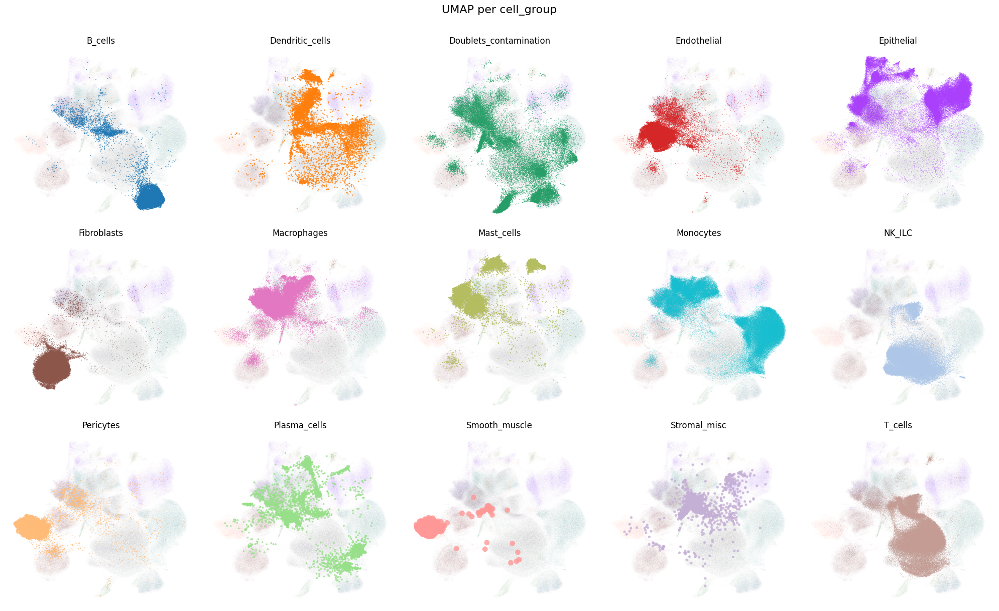

In [54]:
import matplotlib.pyplot as plt
import math

# Rimuovi NaN e converti in stringa
cell_types = sorted(adata_all.obs['cell_group'].dropna().astype(str).unique())
n = len(cell_types)

# Calcola griglia
ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, batch in enumerate(cell_types):
    adata_batch = adata_all[adata_all.obs['cell_group'] == batch]
    
    sc.pl.umap(
        adata_all,          # sfondo grigio con tutte le cellule
        color='cell_group',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        na_color="lightgrey",
        alpha=0.1           # tutte le cellule in grigio trasparente
    )
    # Sovrapponi le cellule del batch in evidenza
    sc.pl.umap(
        adata_batch,
        color='cell_group',
        ax=axes[i],
        show=False,
        frameon=False,
        legend_loc=None,
        title=batch,
        alpha=0.8
    )

# Nascondi i subplot vuoti
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("UMAP per cell_group", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [60]:
other_celltypes = adata_all.obs.loc[adata_all.obs["cell_group"] == "Other", "cell_type"].unique()
other_celltypes

other_celltypes = adata_all.obs.loc[adata_all.obs["cell_group"] == "Other", "dataset"].unique()
other_celltypes


[], Categories (4, object): ['lung', 'pbmc', 'skin', 'synovium']

Plotting: SF1: PRG4+ lining
Plotting: SF2: CHI3L2+ intermediate
Plotting: SF3: APOE+ intermediate
Plotting: SF4: POSTN+ sublining
Plotting: SF5: FKBP5+ sublining
Plotting: SF6: FOSB+ sublining
Plotting: SF7: CXCL14+ sublining
Plotting: SF8: MFAP5+ sublining


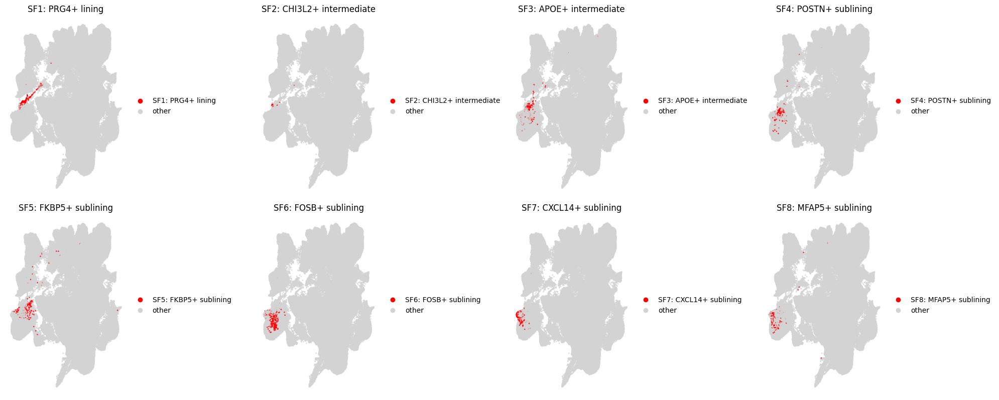

In [61]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

# List of SF cell types to highlight
sf_list = [
    "SF1: PRG4+ lining",
    "SF2: CHI3L2+ intermediate",
    "SF3: APOE+ intermediate",
    "SF4: POSTN+ sublining",
    "SF5: FKBP5+ sublining",
    "SF6: FOSB+ sublining",
    "SF7: CXCL14+ sublining",
    "SF8: MFAP5+ sublining"
]

samples = adata_all.obs["cell_group"].unique()
n = len(samples)

# Choose grid size
cols = 4   # you can increase to 6 or 7 if needed
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4))

# Flatten axes for easier indexing
axes = axes.flatten()

for i, ct in enumerate(sf_list):
    ax = axes[i]

    print(f"Plotting: {ct}")

    # Highlight only this sample
    highlight = adata_all.obs["cell_type"] == ct
    adata_all.obs["highlight_group"] = np.where(highlight, str(ct), "other")

    # Draw UMAP on the chosen axes
    sc.pl.umap(
        adata_all,
        color="highlight_group",
        palette={ct: "red", "other": "lightgrey"},
        size=15,
        alpha=0.8,
        frameon=False,
        title=f"{ct}",
        show=False,
        ax=ax
    )

# Remove unused axes if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Remove temporary column
del adata_all.obs["highlight_group"]




In [62]:
other_celltypes = adata_all.obs.loc[adata_all.obs["cell_type"] == "SF4: POSTN+ sublining", "dataset"].unique()
other_celltypes


['synovium']
Categories (4, object): ['lung', 'pbmc', 'skin', 'synovium']

In [63]:
#adata_all.write("/home/ciperi/data/Atlas_SSC/Fibroblast_populations_corr/Integrated_Atlas_cor.h5ad")

In [64]:
import scanpy as sc
import anndata as ad
import harmonypy as hm
import numpy as np
import random


#adata_all = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Fibroblast_populations_corr/Integrated_Atlas_cor.h5ad")

In [65]:
for batch in adata_all.obs['cell_type'].unique():
    print(batch)

DC2
Classical monocytes
Alveolar macrophages
AT2
Multiciliated
Plasma cells
Monocytes-Mph
CD4 T cellse
EC general capillary
EC venous systemic
NK cells-CD8 T cells
MIXED
Mast cells
Pericytes
Adventitial fibroblasts
AT1
B cells
Goblet cells
Undifferentiated KC
DC1
Differentiated KC
Fibroblast
Macrophages
Schwann_1
Langerhans cells
Erythrocytes
EC arterial
T cells
NK cells
Melanocyte
T cells MT
Natural Killer
CD4 T cells
CD8 T cells
Non-classical monocytes
Megakaryocytes-Platelets
pDC
Natural Killer T
Dendritic cells
Bcells-NK
Platelets-monocyte
Bcells-Tcells
Monocyte-Bcells
Bcells-Platelets
E1: ICAM1+ venous
M0: MERTK+ TIMD4+ macrophages
NK: NK cells
SF4: POSTN+ sublining
M4: S100A12+ monocytes
M6: CD1C+ DCs (DC2/DC3)
E2: LIFR1+ venous
T1: CD4+ IL7R+ Tmem
SF7: CXCL14+ sublining
E5: Lymphatic
SF8: MFAP5+ sublining
T3: CD4+ FOXP3+ Treg
M1: MERTK+ SELENOP+ macrophages
SF3: APOE+ intermediate
T4: CD8+ GRZMK+ T cells
E4: ARL15+ arterial
M3: SPP1+ macrophages
M7: DC4
SF6: FOSB+ sublining
E3: 

In [66]:
import numpy as np
import pandas as pd
import scanpy as sc

#adata_query = sc.read_h5ad("/home/ciperi/data/Atlas_SSC/Fibroblast_populations/Integrated_Atlas.h5ad")

In [67]:
adata_all

AnnData object with n_obs × n_vars = 635633 × 22446
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'characteristics_ch1', 'characteristics_ch1.1', 'characteristics_ch1.2', 'characteristics_ch1.3', 'molecule_ch1', 'extract_protocol_ch1', 'extract_protocol_ch1.1', 'taxid_ch1', 'description', 'description.1', 'description.2', 'data_processing', 'data_processing.1', 'data_processing.2', 'data_processing.3', 'data_processing.4', 'platform_id', 'contact_name', 'contact_laboratory', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip_postal_code', 'contact_country', 'data_row_count', 'instrument_model', 'library_selection', 'library_source', 'library_strategy', 'relation', 'supple

In [68]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 2000
groupby = "leiden_global"

# Usa indici numerici invece dei nomi dei barcodes
subsampled_idx = []

for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():
    # Converti i nomi in posizioni numeriche
    positions = np.where(adata_all.obs.index.isin(indices))[0]
    n_cells = len(positions)
    
    if n_cells <= min_keep:
        chosen = positions
    else:
        chosen = np.random.choice(positions, size=min_keep, replace=False)
    
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Usa iloc-style indexing con indici numerici
adata_sub = adata_all[np.array(subsampled_idx), :].copy()

print(f"\nTotal cells before: {adata_all.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")

0                    → kept 2000 / 35440 cells
1                    → kept 2000 / 79928 cells
2                    → kept 2000 / 28203 cells
3                    → kept 2000 / 95442 cells
4                    → kept 2000 / 96526 cells


/tmp/ipykernel_3149117/620974648.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cell_type, indices in adata_all.obs.groupby(groupby).groups.items():


5                    → kept 2000 / 113515 cells
6                    → kept 2000 / 16879 cells
7                    → kept 2000 / 19848 cells
8                    → kept 2000 / 16062 cells
9                    → kept 2000 / 17914 cells
10                   → kept 2000 / 138354 cells
11                   → kept 2000 / 3110 cells
12                   → kept 2000 / 13880 cells
13                   → kept 2000 / 74341 cells
14                   → kept 2000 / 98969 cells
15                   → kept 2000 / 45606 cells
16                   → kept 2000 / 23686 cells
17                   → kept 2000 / 21885 cells
18                   → kept 2000 / 28168 cells
19                   → kept 1518 / 1518 cells
20                   → kept 2000 / 94258 cells
21                   → kept 2000 / 43039 cells
22                   → kept 2000 / 20366 cells
23                   → kept 2000 / 10350 cells
24                   → kept 2000 / 27318 cells
25                   → kept 2000 / 52194 cells
26           

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/anndata/_core/anndata.py:1791: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


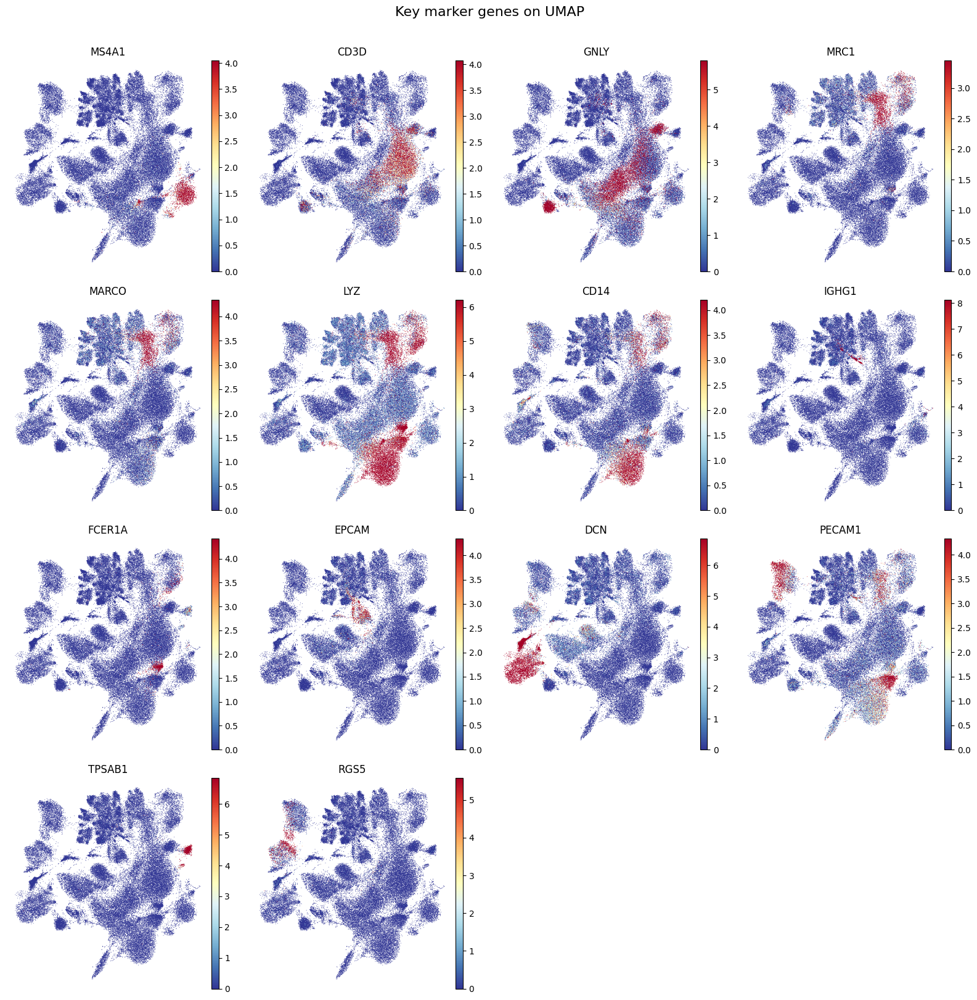

In [69]:
import matplotlib.pyplot as plt
import math

markers = {
    "B cells":       ["MS4A1"],           # CD20 — canonico e universale
    "T cells":       ["CD3D"],            # CD3 — pan-T
    "NK cells":      ["GNLY"],            # granulisina — pan-NK
    "Macrophages":   ["MRC1", "MARCO"],   # CD206 — pan-macrofagi
    "Monocytes":     ["LYZ", "CD14"],     # pan-monociti
    "Plasma cells":  ["IGHG1"],           # immunoglobulina — plasma cells
    "DC":            ["FCER1A"],          # recettore IgE — DC2/pan-DC
    "Epithelial":    ["EPCAM"],           # pan-epiteliale
    "Fibroblasts":   ["DCN"],             # decorina — pan-fibroblasti
    "Endothelial":   ["PECAM1"],          # CD31 — pan-endoteliale
    "Mast cells":    ["TPSAB1"],          # triptasi — pan-mast
    "Pericytes":     ["RGS5"],            # pan-periciti
}

# Flatten tutti i geni
all_markers = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"⚠️ Marker mancanti: {missing}")

# Plot
n = len(all_markers)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
axes = axes.flatten()

for i, gene in enumerate(all_markers):
    sc.pl.umap(
        adata_sub,
        color=gene,
        ax=axes[i],
        show=False,
        frameon=False,
        title=gene,
        cmap="RdYlBu_r",
        vmin=0,
        vmax=adata_sub[:, gene].X.max() if hasattr(adata_sub[:, gene].X, 'max') else None,
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Key marker genes on UMAP", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

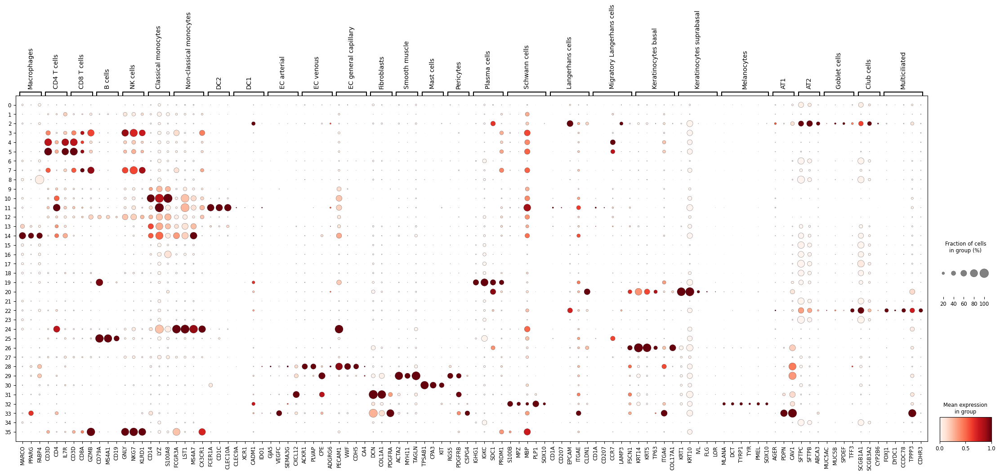

In [70]:
markers = {
    "Macrophages":     ["MARCO", "PPARG", "FABP4"],
    "CD4 T cells":              ["CD3D", "CD4", "IL7R"],
    "CD8 T cells":              ["CD3D", "CD8A", "GZMB"],
    "B cells":                  ["CD79A", "MS4A1", "CD19"],
    "NK cells":                 ["GNLY", "NKG7", "KLRD1"],
    "Classical monocytes":      ["CD14", "LYZ", "S100A8"],
    "Non-classical monocytes":  ["FCGR3A", "LST1", "MS4A7", "CX3CR1"],
    "DC2":                      ["FCER1A", "CD1C", "CLEC10A"],
    "DC1":                      ["CLEC9A", "XCR1", "CADM1", "IDO1"],
    "EC arterial":              ["GJA5", "VEGFC", "SEMA3G", "CXCL12"],   # ← aggiunto
    "EC venous":                ["ACKR1", "PLVAP", "CPE", "ADGRG6"],     # ← aggiunto
    "EC general capillary":     ["PECAM1", "VWF", "CDH5", "CA4"],        # ← aggiunto CA4
    "Fibroblasts":              ["DCN", "COL1A1", "PDGFRA"],
    "Smooth muscle":            ["ACTA2", "MYH11", "TAGLN"],
    "Mast cells":               ["TPSAB1", "CPA3", "KIT"],
    "Pericytes":                ["RGS5", "PDGFRB", "CSPG4"],
    "Plasma cells":             ["IGHG1", "IGKC", "SDC1", "PRDM1"],
    "Schwann cells":            ["S100B", "MPZ", "MBP", "PLP1", "SOX10"],
    "Langerhans cells":         ["CD1A", "CD207", "EPCAM", "ITGAE", "CLDN1"],
    "Migratory Langerhans cells": ["CD1A", "CD207", "CCR7", "LAMP3", "FSCN1"],
    "Keratinocytes basal":      ["KRT14", "KRT5", "TP63", "ITGA6", "COL17A1"],
    "Keratinocytes suprabasal": ["KRT1", "KRT10", "IVL", "FLG", "LOR"],
    "Melanocytes":              ["MLANA", "DCT", "TYRP1", "TYR", "PMEL", "SOX10"],
    "AT1":                      ["AGER", "PDPN", "CAV1"],
    "AT2":                      ["SFTPC", "SFTPB", "ABCA3"],
    "Goblet cells":             ["MUC5AC", "MUC5B", "SPDEF", "TFF3"],
    "Club cells":               ["SCGB1A1", "SCGB3A2", "CYP2B6"],
    "Multiciliated":            ["FOXJ1", "DYDC1", "CCDC78", "TPPP3", "CDHR3"],
}

# Filtra i marker presenti nel dataset
all_markers_flat = [g for genes in markers.values() for g in genes if g in adata_sub.var_names]

# Verifica quali marker mancano
missing = [g for genes in markers.values() for g in genes if g not in adata_sub.var_names]
if missing:
    print(f"Marker non trovati nel dataset: {missing}")

sc.pl.dotplot(
    adata_sub,
    var_names=markers,
    groupby="leiden_global",
    standard_scale="var",
    figsize=(28, 10),
)

In [63]:
adata_all.write("/home/ciperi/data/Atlas_SSC/Fibroblast_populations_corr/Integrated_Atlas_cor.h5ad")